# E-Commerce Customer Purchase Prediction Using Logistic Regression
**Company:** ShopSmart | **Domain:** E-Commerce | **Task:** Binary classification (0 = No Purchase, 1 = Purchase)

This notebook covers the full workflow: EDA, preprocessing (missing values, outliers, encoding, scaling), Logistic Regression modelling and tuning, evaluation, interpretation, predictions for new customers and business recommendations.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve,
                             average_precision_score, ConfusionMatrixDisplay)
import joblib
from iqr_capper import IQRCapper   # custom IQR outlier-capping transformer (shipped alongside)

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42
DATA_PATH = 'Ecommerce_Purchase_Prediction_DataSet.csv'
FIG_DIR, ART_DIR = 'figures', 'artifacts'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(ART_DIR, exist_ok=True)
RESULTS = {}

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=120, bbox_inches='tight')
    plt.show()

## 1. Data understanding & exploratory data analysis

In [2]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
display(df.head())
df.info()
display(df.describe().T)
RESULTS['n_rows'], RESULTS['n_cols'] = int(df.shape[0]), int(df.shape[1])

Shape: (10000, 19)


,Customer_ID,Age,Gender,Device_Type,Traffic_Source,Membership_Type,Payment_Method,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year,Purchase
0,CUST00001,37.0,Female,Mobile,Referral,Regular,Credit Card,6.78,5.0,8,0,4933.27,14.05,2,3.09,0.273,4.07,1,1
1,CUST00002,24.0,Male,Mobile,Organic,Premium,Debit Card,12.79,9.0,5,1,3042.60,7.28,2,48.27,0.045,4.19,0,1
2,CUST00003,42.0,Female,Mobile,Referral,Regular,Wallet,11.72,9.0,5,1,NaN,9.77,4,3.82,0.796,3.37,2,0
3,CUST00004,43.0,Male,Tablet,Referral,Premium,UPI,10.67,7.0,6,3,2776.48,6.78,0,9.24,0.426,5.00,1,1
4,CUST00005,18.0,Male,Desktop,Social Media,Regular,Debit Card,12.06,4.0,3,4,3683.66,16.37,4,4.46,0.347,2.16,0,1


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  str    
 1   Age                    9762 non-null   float64
 2   Gender                 9796 non-null   str    
 3   Device_Type            9855 non-null   str    
 4   Traffic_Source         9760 non-null   str    
 5   Membership_Type        9791 non-null   str    
 6   Payment_Method         9787 non-null   str    
 7   Session_Duration_Min   9776 non-null   float64
 8   Pages_Viewed           10000 non-null  float64
 9   Products_Viewed        10000 non-null  int64  
 10  Cart_Items             10000 non-null  int64  
 11  Cart_Value_INR         9675 non-null   float64
 12  Discount_Percent       9789 non-null   float64
 13  Previous_Orders        10000 non-null  int64  
 14  Days_Since_Last_Visit  9820 non-null   float64
 15  Email_Open_Rat

,count,mean,std,min,25%,50%,75%,max
Age,9762.0,34.127228,9.546429,18.00,27.000,34.000,40.00000,74.000000
Session_Duration_Min,9776.0,13.117865,12.737399,1.00,6.780,10.835,16.64250,227.756046
Pages_Viewed,10000.0,7.274137,6.055331,1.00,5.000,7.000,9.00000,148.075292
Products_Viewed,10000.0,3.991100,1.999555,0.00,3.000,4.000,5.00000,12.000000
Cart_Items,10000.0,1.523000,1.228015,0.00,1.000,1.000,2.00000,7.000000
Cart_Value_INR,9675.0,1912.614298,3831.569883,14.93,819.930,1433.270,2279.96500,88342.757367
Discount_Percent,9789.0,12.178725,8.143978,0.14,6.450,10.820,16.22000,99.149690
Previous_Orders,10000.0,2.997800,1.725947,0.00,2.000,3.000,4.00000,15.000000
Days_Since_Last_Visit,9820.0,13.314532,26.690252,0.00,3.460,8.470,16.74500,671.772129
Email_Open_Rate,10000.0,0.500227,0.290871,0.00,0.246,0.502,0.75125,1.000000


### 1.1 Target distribution

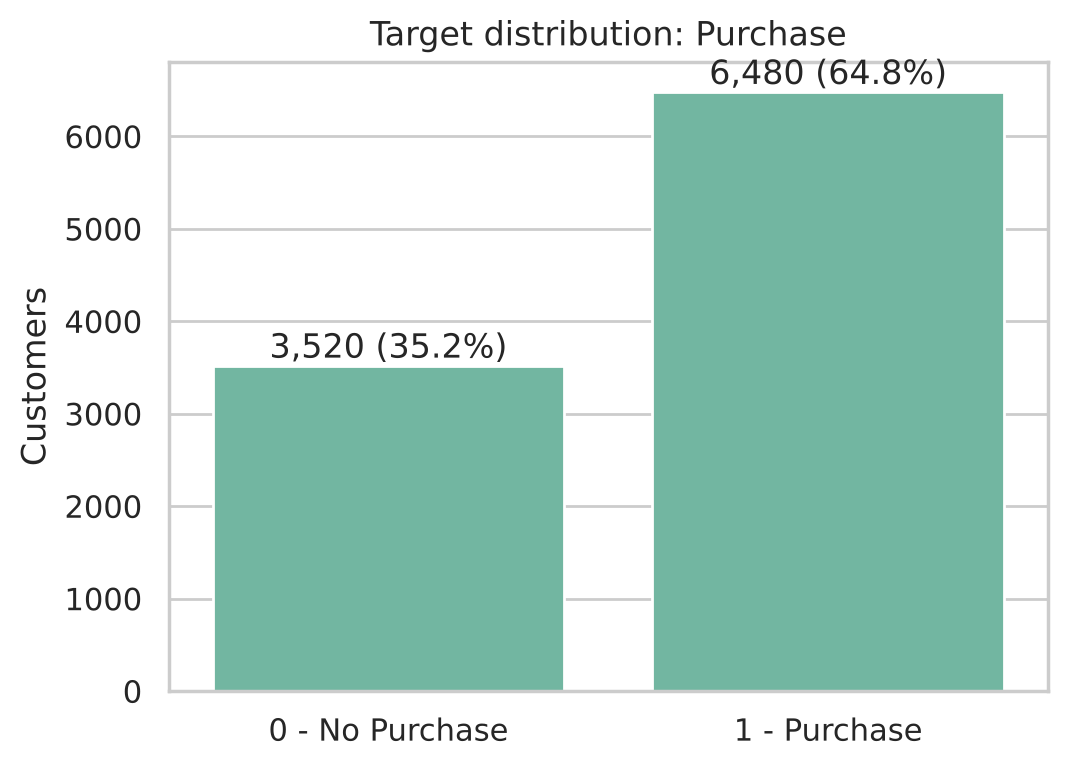

In [3]:
vc = df['Purchase'].value_counts().sort_index()
RESULTS['class_counts'] = {int(k): int(v) for k, v in vc.items()}
RESULTS['purchase_rate'] = float(df['Purchase'].mean())
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.barplot(x=['0 - No Purchase', '1 - Purchase'], y=vc.values, ax=ax)
ax.bar_label(ax.containers[0], labels=[f'{v:,} ({v/len(df):.1%})' for v in vc.values])
ax.set_title('Target distribution: Purchase'); ax.set_ylabel('Customers')
savefig('01_target_distribution')

### 1.2 Missing values

,missing,pct
Customer_Rating,325,3.25
Cart_Value_INR,325,3.25
Traffic_Source,240,2.40
Age,238,2.38
Session_Duration_Min,224,2.24
Payment_Method,213,2.13
Discount_Percent,211,2.11
Membership_Type,209,2.09
Gender,204,2.04
Days_Since_Last_Visit,180,1.80


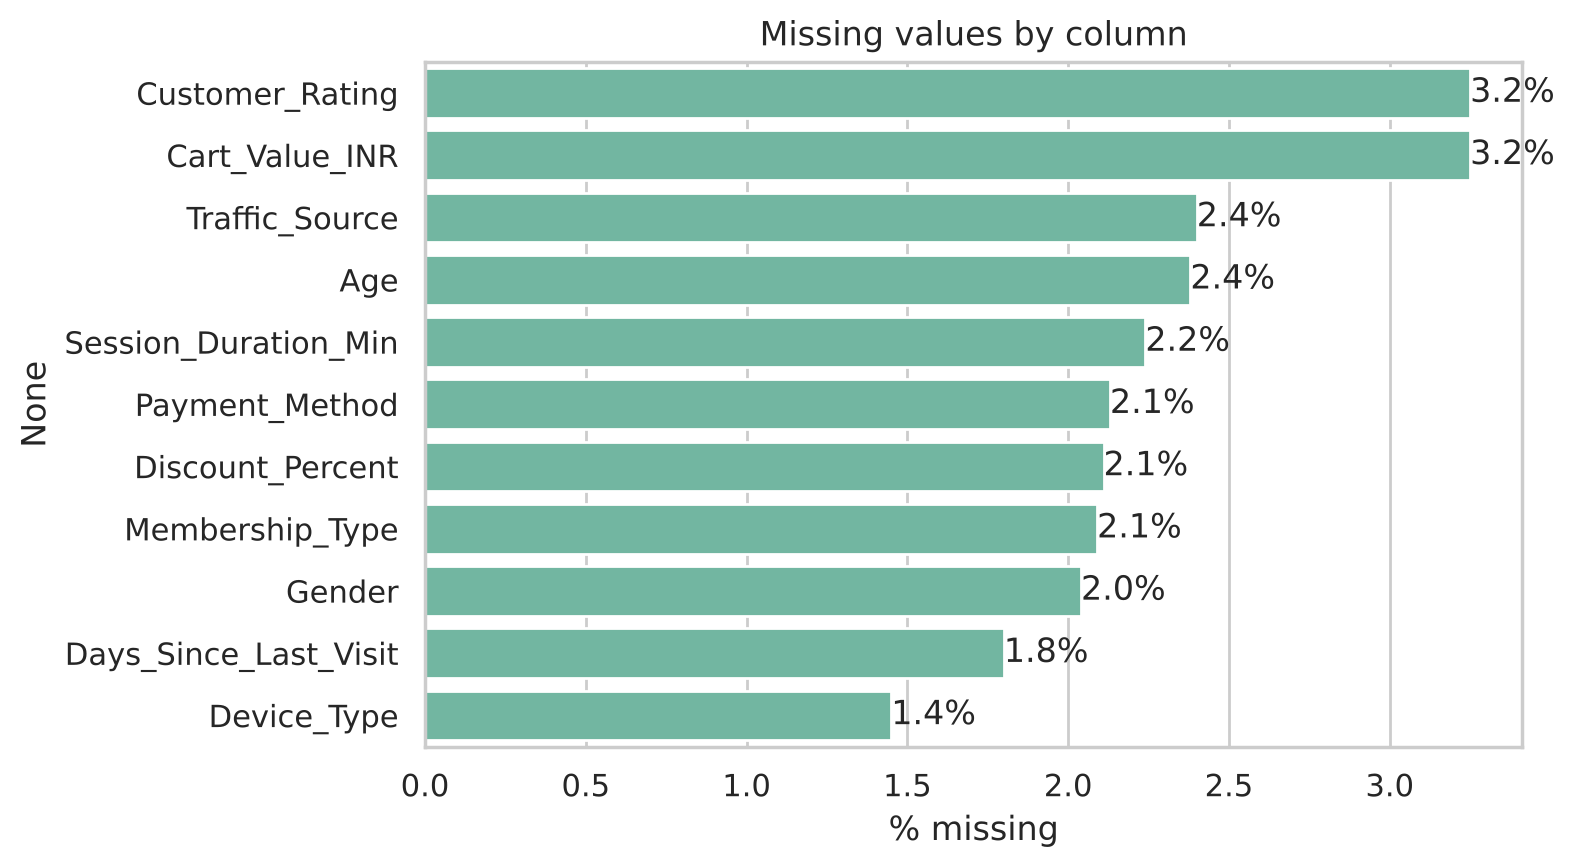

,column,purchase_rate_if_present,purchase_rate_if_missing
0,Customer_Rating,0.648,0.640
1,Cart_Value_INR,0.649,0.618
2,Traffic_Source,0.648,0.642
3,Age,0.648,0.643
4,Session_Duration_Min,0.649,0.621
5,Payment_Method,0.648,0.629
6,Discount_Percent,0.650,0.578
7,Membership_Type,0.648,0.636
8,Gender,0.648,0.642
9,Days_Since_Last_Visit,0.646,0.739


In [4]:
miss = pd.DataFrame({'missing': df.isna().sum(), 'pct': (df.isna().mean()*100).round(2)})
miss = miss[miss.missing > 0].sort_values('missing', ascending=False)
display(miss)
RESULTS['missing'] = {k: int(v) for k, v in miss['missing'].items()}
RESULTS['total_missing_cells'] = int(df.isna().sum().sum())
RESULTS['rows_with_any_missing'] = int(df.isna().any(axis=1).sum())
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=miss['pct'], y=miss.index, ax=ax, color='#66c2a5')
ax.bar_label(ax.containers[0], fmt='%.1f%%'); ax.set_xlabel('% missing'); ax.set_title('Missing values by column')
savefig('02_missing_values')

# Is missingness related to the target? (checks whether 'missing' itself is informative)
rows = []
for c in miss.index:
    g = df.groupby(df[c].isna())['Purchase'].mean()
    rows.append({'column': c, 'purchase_rate_if_present': g.get(False), 'purchase_rate_if_missing': g.get(True)})
display(pd.DataFrame(rows).round(3))

### 1.3 Data-quality checks (duplicates, invalid and impossible values)

In [5]:
num_cols_all = ['Age','Session_Duration_Min','Pages_Viewed','Products_Viewed','Cart_Items','Cart_Value_INR',
                'Discount_Percent','Previous_Orders','Days_Since_Last_Visit','Email_Open_Rate','Customer_Rating','Returns_Last_Year']
cat_cols_all = ['Gender','Device_Type','Traffic_Source','Membership_Type','Payment_Method']
checks = {
 'duplicate rows': int(df.duplicated().sum()),
 'duplicate Customer_ID': int(df['Customer_ID'].duplicated().sum()),
 'Age < 18 or > 100': int(((df.Age < 18) | (df.Age > 100)).sum()),
 'Email_Open_Rate outside [0,1]': int(((df.Email_Open_Rate < 0) | (df.Email_Open_Rate > 1)).sum()),
 'Customer_Rating outside [1,5]': int(((df.Customer_Rating < 1) | (df.Customer_Rating > 5)).sum()),
 'Discount_Percent outside [0,100]': int(((df.Discount_Percent < 0) | (df.Discount_Percent > 100)).sum()),
 'negative values in any numeric column': int((df[num_cols_all] < 0).any(axis=1).sum()),
 'Pages_Viewed not a whole number': int((df.Pages_Viewed.dropna() % 1 != 0).sum()),
 'Age not a whole number': int((df.Age.dropna() % 1 != 0).sum()),
 'Cart_Items = 0 but Cart_Value > 0': int(((df.Cart_Items == 0) & (df.Cart_Value_INR > 0)).sum()),
}
RESULTS['quality_checks'] = checks
display(pd.Series(checks, name='count').to_frame())
print('Categorical levels:')
for c in cat_cols_all: print(f'  {c}:', df[c].dropna().unique().tolist())

,count
duplicate rows,0
duplicate Customer_ID,0
Age < 18 or > 100,0
"Email_Open_Rate outside [0,1]",0
"Customer_Rating outside [1,5]",0
"Discount_Percent outside [0,100]",0
negative values in any numeric column,0
Pages_Viewed not a whole number,30
Age not a whole number,0
Cart_Items = 0 but Cart_Value > 0,2105


Categorical levels:
  Gender: ['Female', 'Male', 'Other']
  Device_Type: ['Mobile', 'Tablet', 'Desktop']
  Traffic_Source: ['Referral', 'Organic', 'Social Media', 'Paid Ads', 'Email']
  Membership_Type: ['Regular', 'Premium', 'New']
  Payment_Method: ['Credit Card', 'Debit Card', 'Wallet', 'UPI', 'Cash on Delivery']


### 1.4 Distributions of numeric features

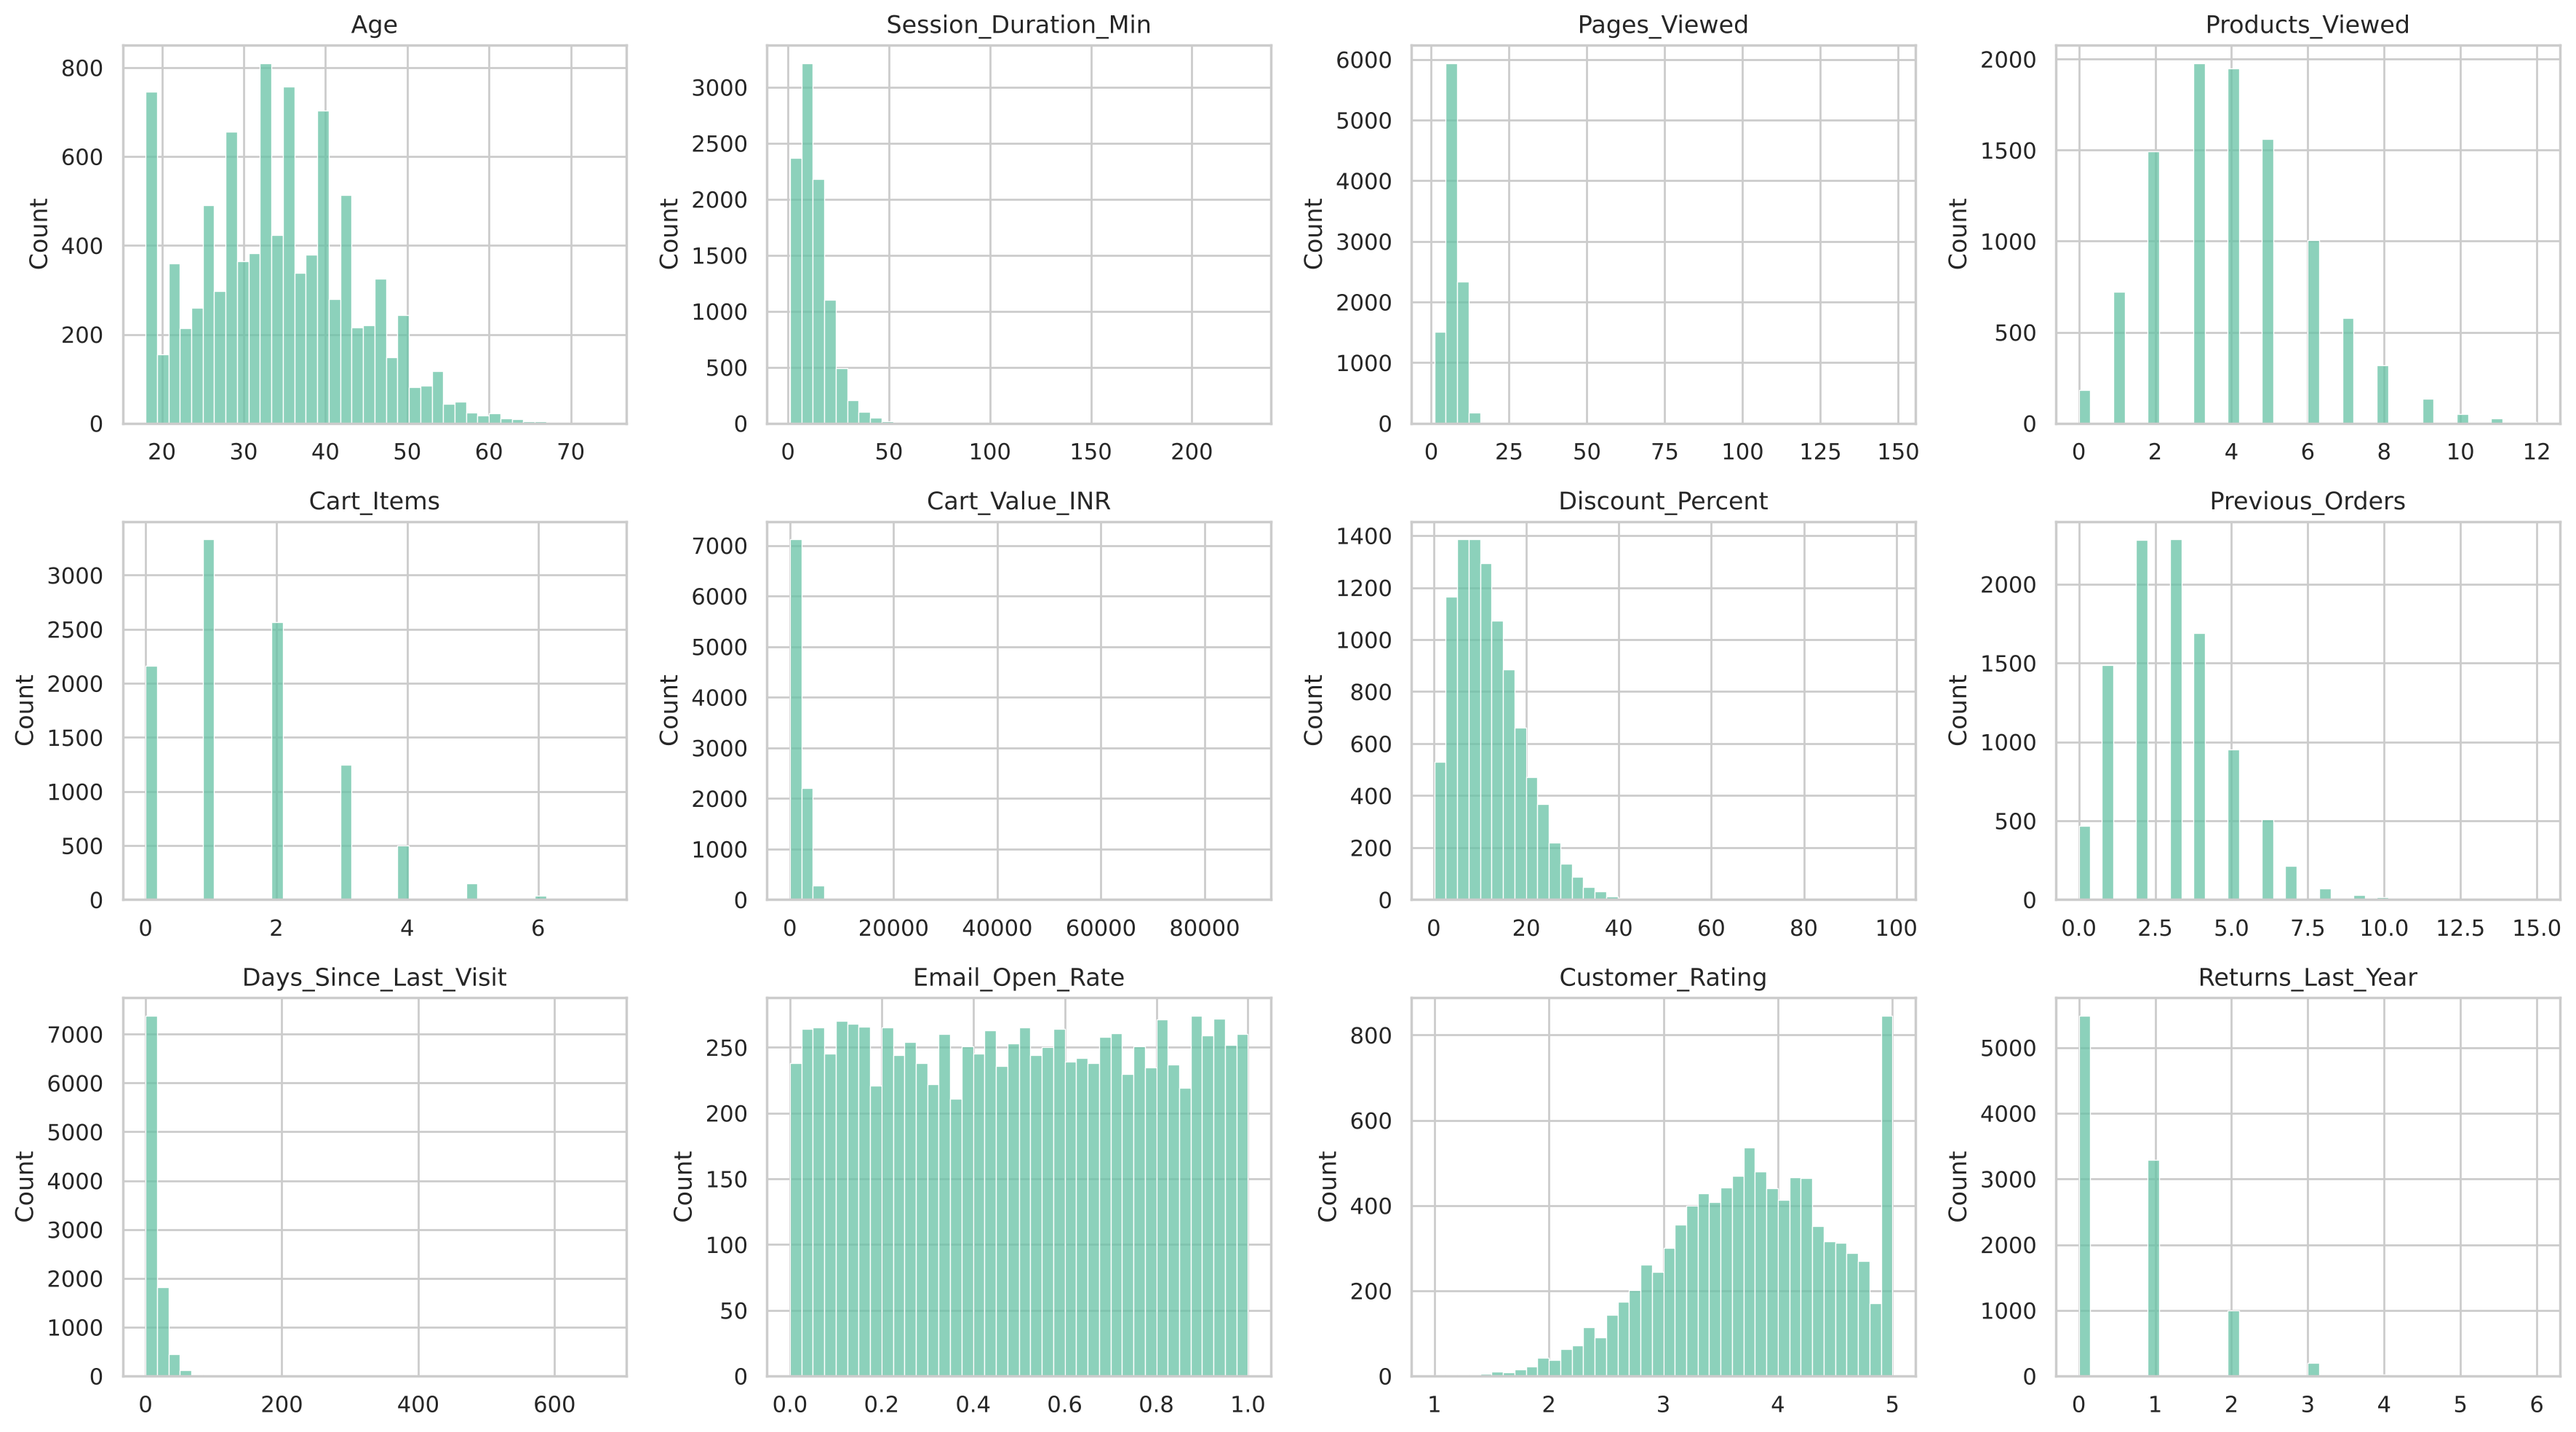

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10)); axes = axes.ravel()
for ax, c in zip(axes, num_cols_all):
    sns.histplot(df[c].dropna(), bins=40, kde=False, ax=ax, color='#66c2a5'); ax.set_title(c); ax.set_xlabel('')
savefig('03_numeric_distributions')

### 1.5 Outlier detection (IQR rule)

In [7]:
cont_cols = ['Age','Session_Duration_Min','Pages_Viewed','Cart_Value_INR','Discount_Percent','Days_Since_Last_Visit']
rows = []
for c in cont_cols:
    s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append({'feature': c, 'Q1': q1, 'Q3': q3, 'lower_fence': lo, 'upper_fence': hi,
                 'n_below': int((s < lo).sum()), 'n_above': int((s > hi).sum()),
                 'pct_outliers': round(100*((s < lo) | (s > hi)).mean(), 2), 'min': s.min(), 'max': s.max()})
outlier_tbl = pd.DataFrame(rows).round(2)
display(outlier_tbl)
RESULTS['outliers_raw'] = outlier_tbl.to_dict(orient='records')

,feature,Q1,Q3,lower_fence,upper_fence,n_below,n_above,pct_outliers,min,max
0,Age,27.00,40.00,7.50,59.50,0,58,0.59,18.00,74.00
1,Session_Duration_Min,6.78,16.64,-8.01,31.44,0,325,3.32,1.00,227.76
2,Pages_Viewed,5.00,9.00,-1.00,15.00,0,45,0.45,1.00,148.08
3,Cart_Value_INR,819.93,2279.96,-1370.12,4470.02,0,346,3.58,14.93,88342.76
4,Discount_Percent,6.45,16.22,-8.20,30.88,0,176,1.80,0.14,99.15
5,Days_Since_Last_Visit,3.46,16.74,-16.47,36.67,0,508,5.17,0.00,671.77


### 1.6 Purchase rate by categorical features

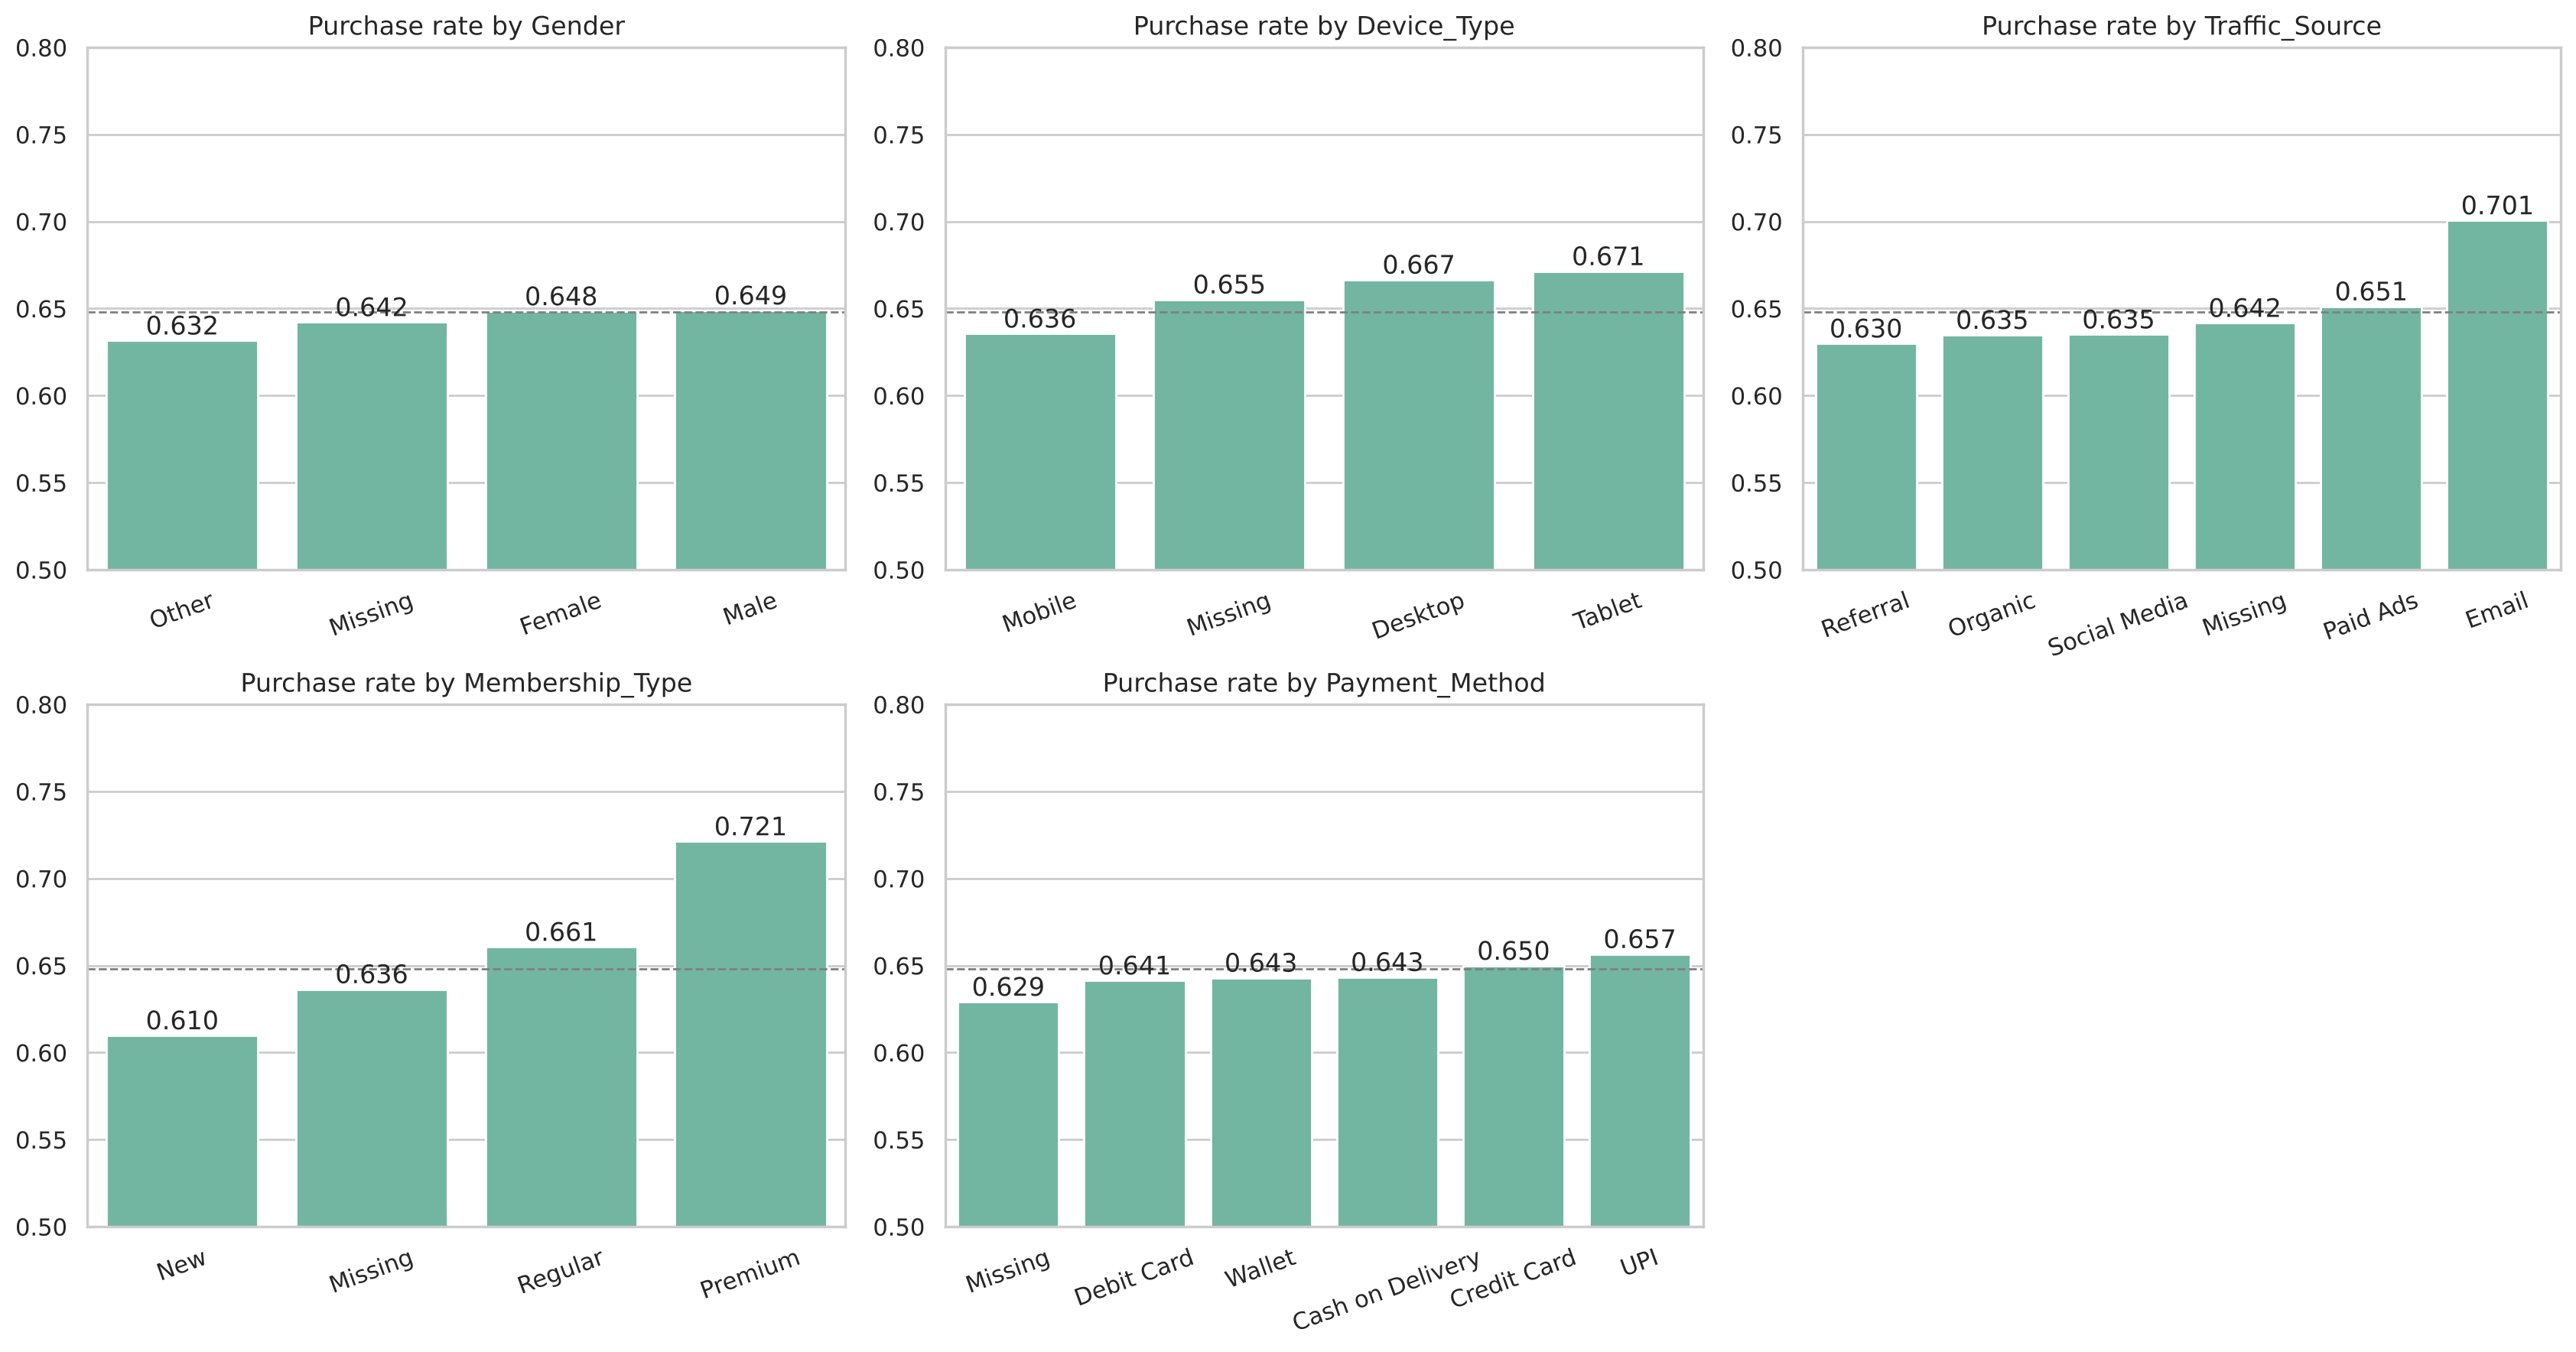

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9)); axes = axes.ravel()
base = df.Purchase.mean()
for ax, c in zip(axes, cat_cols_all):
    s = df[c].fillna('Missing')
    rate = df.groupby(s)['Purchase'].mean().sort_values()
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color='#66c2a5')
    ax.bar_label(ax.containers[0], fmt='%.3f'); ax.axhline(base, ls='--', color='gray', lw=1)
    ax.set_ylim(0.5, 0.8); ax.set_title(f'Purchase rate by {c}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
axes[-1].axis('off')
savefig('04_purchase_rate_categorical')
cat_rates = {c: df.groupby(df[c].fillna('Missing'))['Purchase'].mean().round(4).to_dict() for c in cat_cols_all}
RESULTS['purchase_rate_by_category'] = cat_rates

### 1.7 Purchase rate vs numeric features

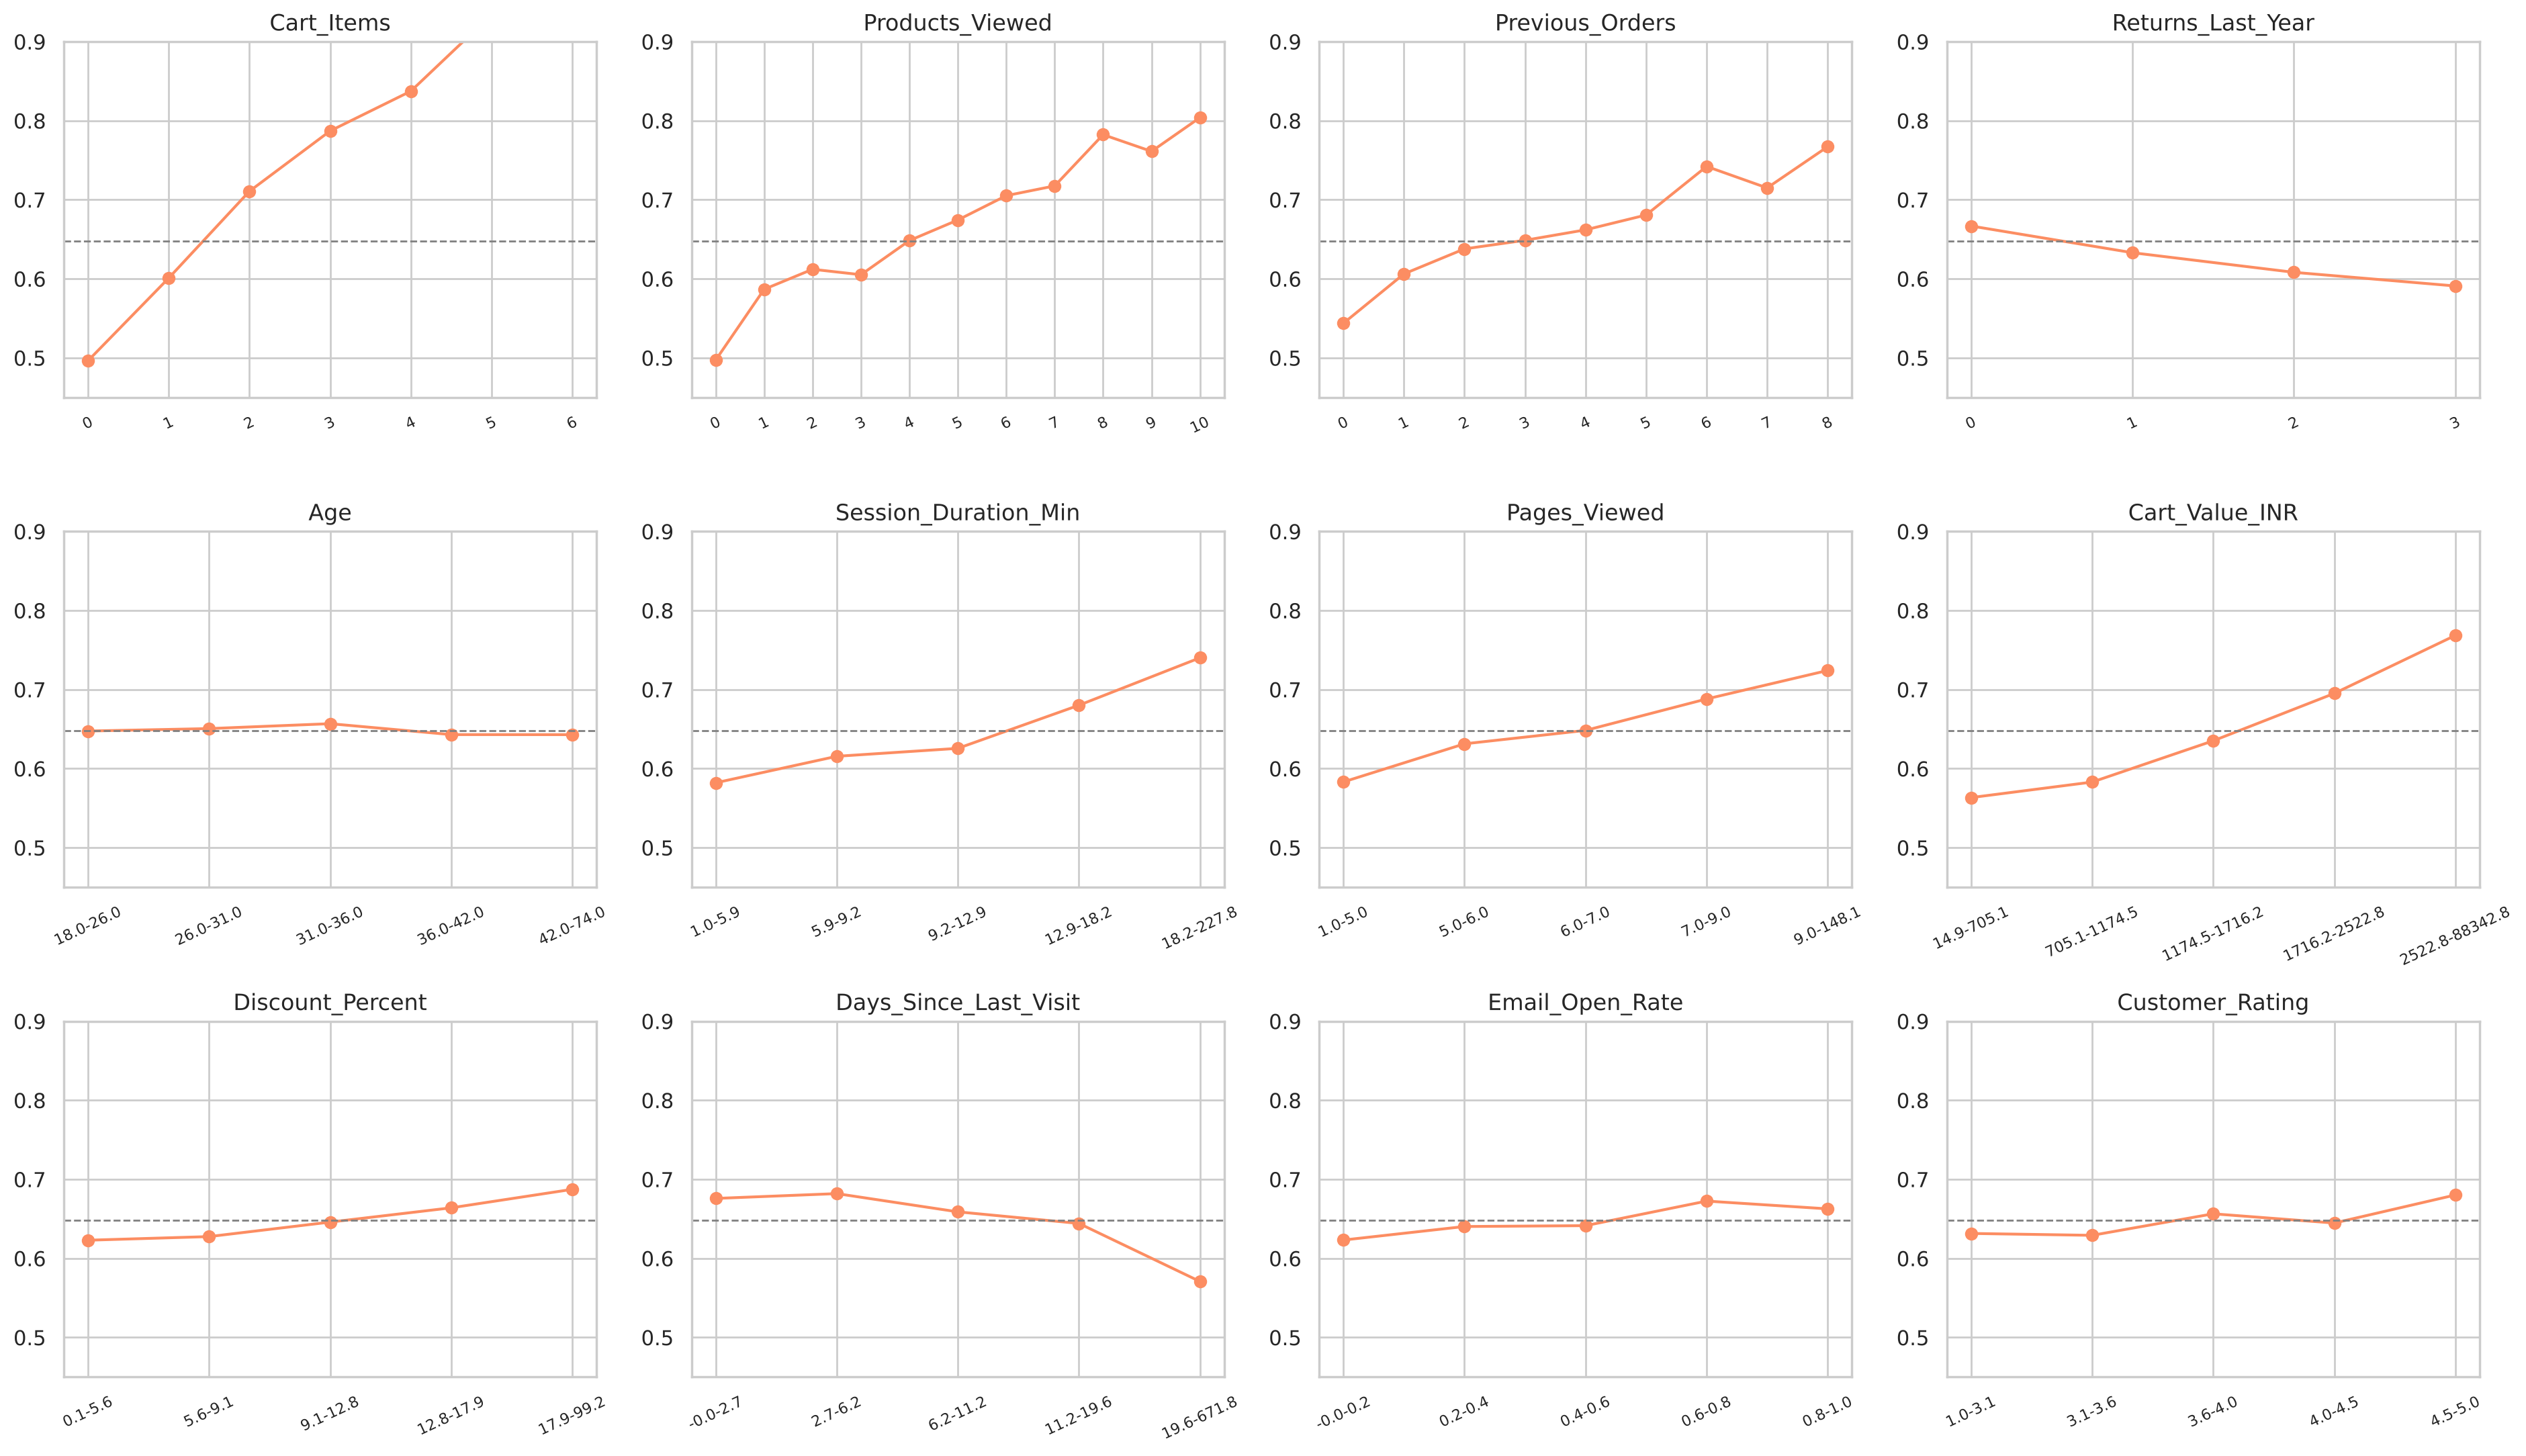

In [9]:
discrete = ['Cart_Items','Products_Viewed','Previous_Orders','Returns_Last_Year']
continuous = ['Age','Session_Duration_Min','Pages_Viewed','Cart_Value_INR','Discount_Percent','Days_Since_Last_Visit','Email_Open_Rate','Customer_Rating']
fig, axes = plt.subplots(3, 4, figsize=(19, 11)); axes = axes.ravel()
for ax, c in zip(axes, discrete + continuous):
    if c in discrete:
        g = df.groupby(c)['Purchase'].agg(['mean', 'count']); g = g[g['count'] >= 30]; labels = [str(i) for i in g.index]
    else:
        g = df.groupby(pd.qcut(df[c], 5, duplicates='drop'), observed=True)['Purchase'].agg(['mean', 'count'])
        labels = [f'{i.left:.1f}-{i.right:.1f}' for i in g.index]
    ax.plot(range(len(g)), g['mean'].values, marker='o', color='#fc8d62'); ax.axhline(base, ls='--', color='gray', lw=1)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(labels, rotation=25, fontsize=8); ax.set_title(c); ax.set_ylim(0.45, 0.9)
savefig('05_purchase_rate_numeric')

### 1.8 Correlation heatmap

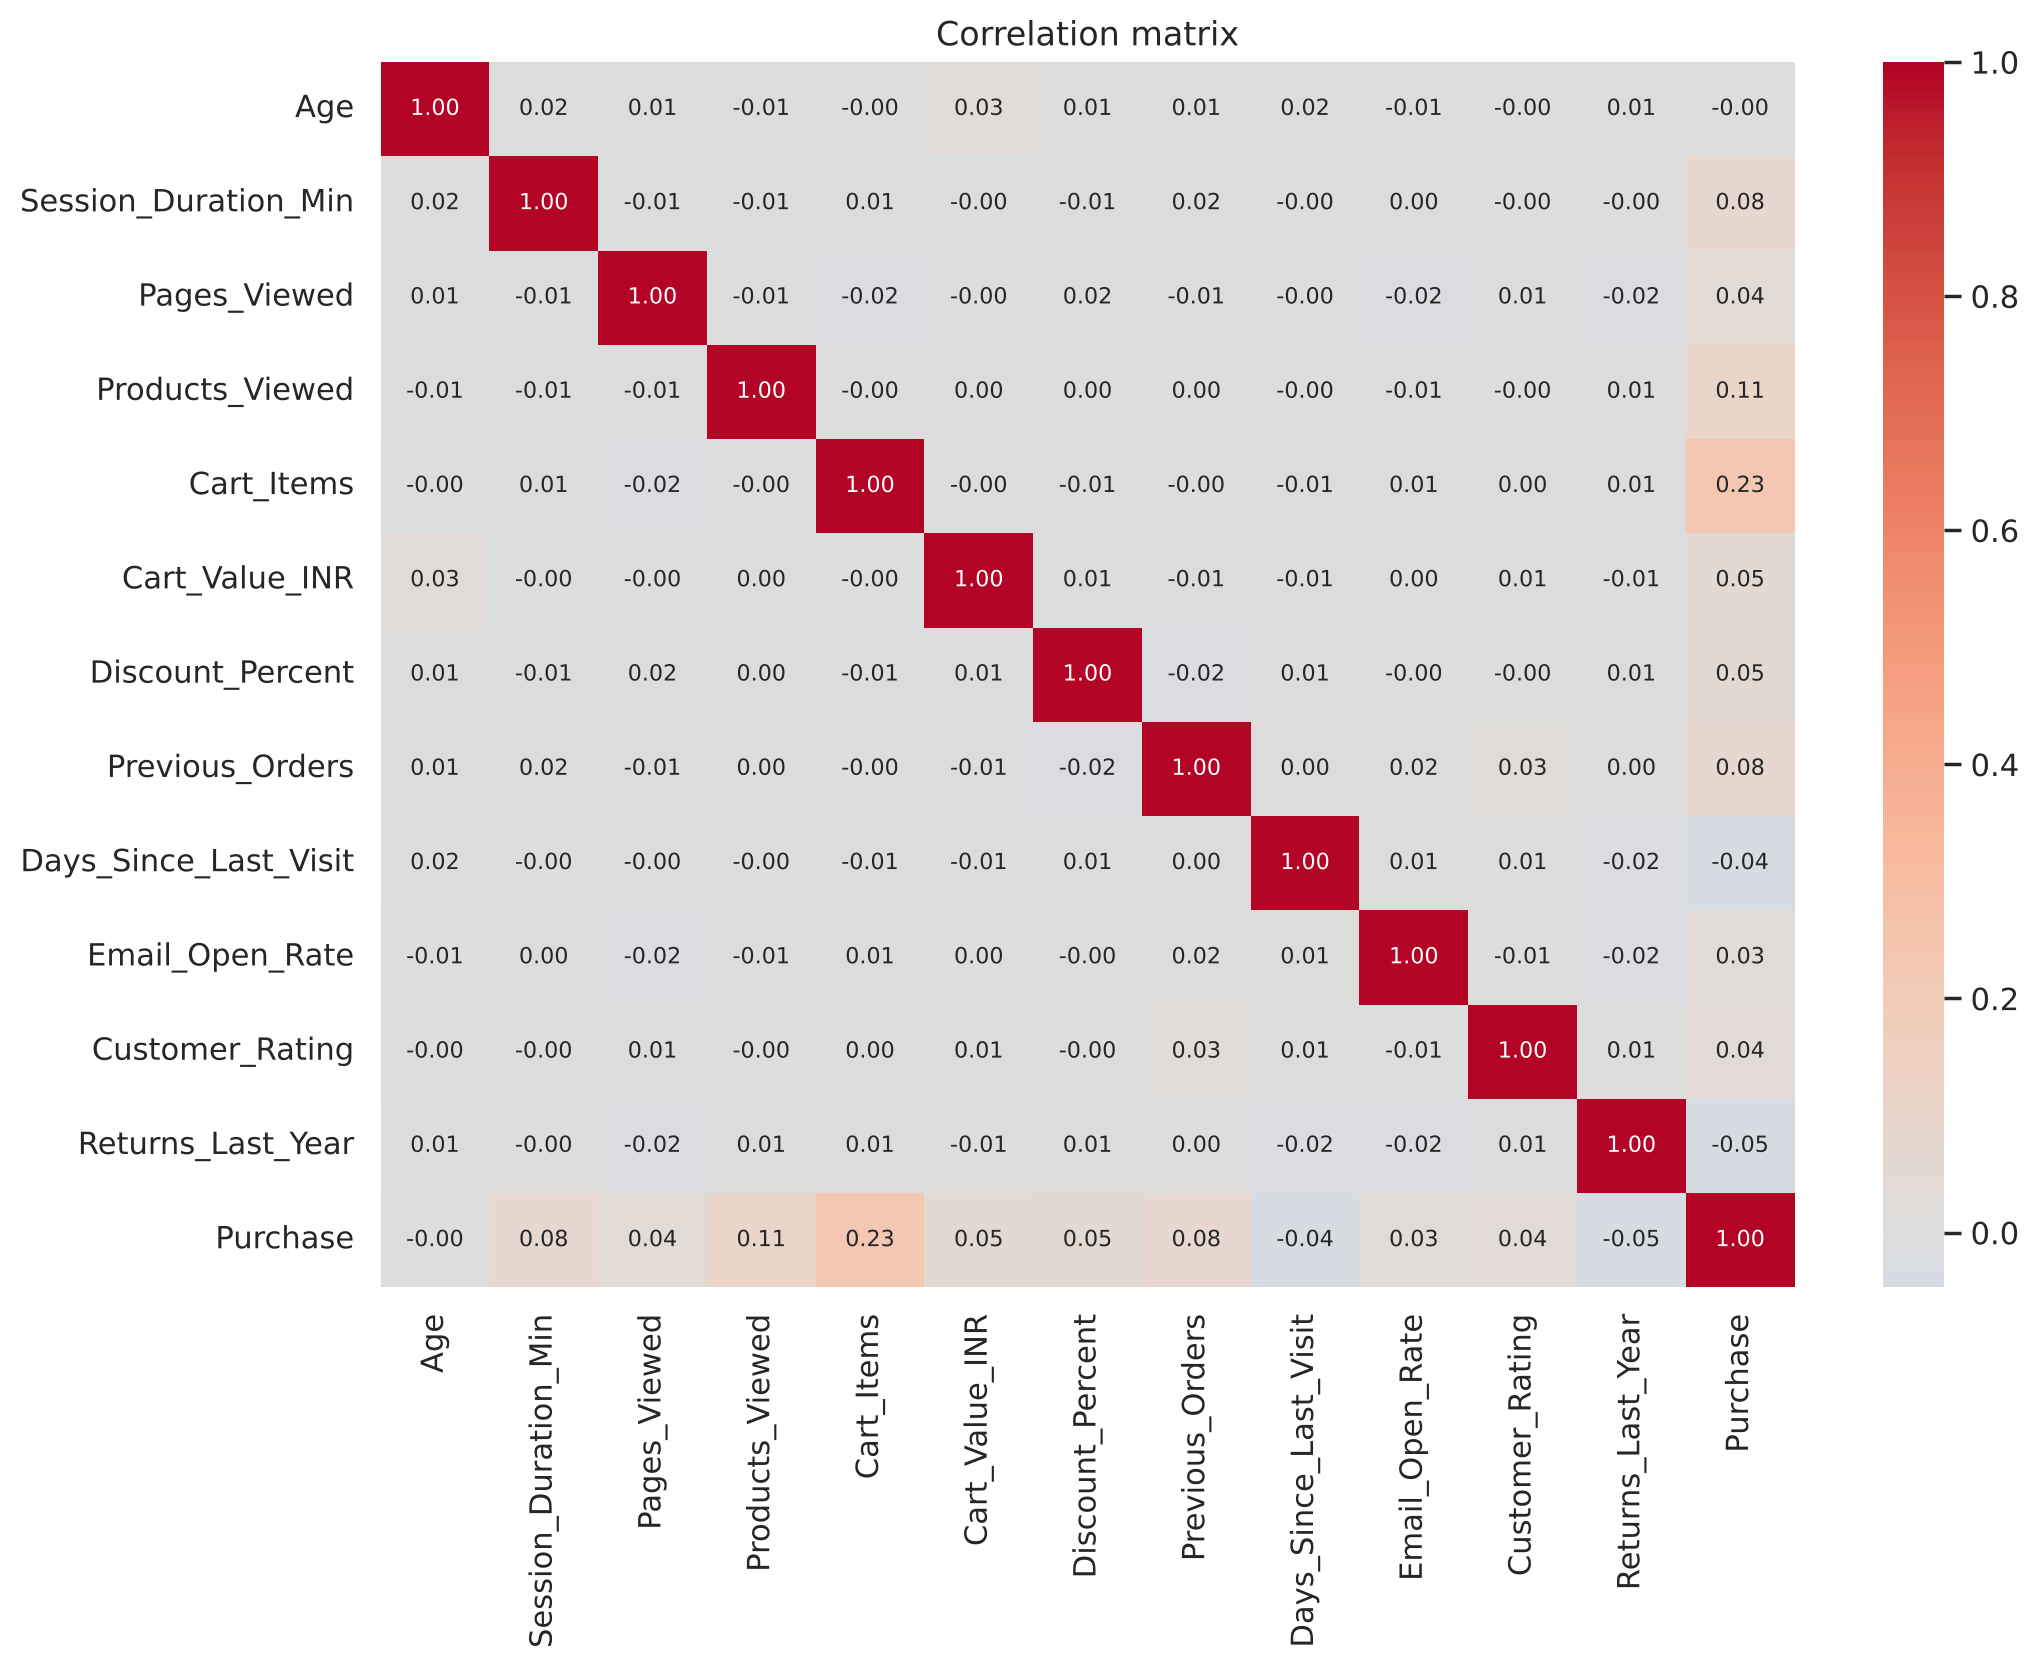

,corr_with_Purchase
Returns_Last_Year,-0.047
Days_Since_Last_Visit,-0.043
Age,-0.001
Email_Open_Rate,0.032
Customer_Rating,0.037
Pages_Viewed,0.042
Discount_Percent,0.050
Cart_Value_INR,0.054
Session_Duration_Min,0.079
Previous_Orders,0.082


In [10]:
corr = df[num_cols_all + ['Purchase']].corr()
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, annot_kws={'size': 8}); ax.set_title('Correlation matrix')
savefig('06_correlation_heatmap')
tc = corr['Purchase'].drop('Purchase').sort_values()
RESULTS['corr_with_target'] = tc.round(4).to_dict()
display(tc.to_frame('corr_with_Purchase').round(3))

### Key EDA insights
1. **Class balance:** 64.8% of customers purchased (6,480) vs 35.2% who did not (3,520). Moderately imbalanced; a model that always predicts "Purchase" would already score 64.8% accuracy, so that is the benchmark to beat.
2. **Missing data:** 2,514 missing cells across 11 columns, touching 2,222 rows (22%). Each affected column is only about 1.5%-3.3% missing, and missingness has no strong link to the target (the biggest gaps, in Discount_Percent and Days_Since_Last_Visit, rest on only ~200 rows each), so simple imputation is reasonable.
3. **Cart size is the strongest signal:** purchase rate climbs steadily from 49.6% with 0 cart items to 60.1% (1 item), 71.1% (2), 78.7% (3), 83.7% (4) and 93.4% (5 items).
4. **Membership matters:** Premium 72.1% > Regular 66.1% > New 61.0%.
5. **Traffic source:** Email visitors convert best (70.1%); Organic, Referral and Social Media are lowest (about 63-64%).
6. **Recency and returns:** customers who visited in the last 7 days convert at 67.9% vs 54.7% for those absent for 30+ days; purchase rate also declines with more returns last year.
7. **Gender, age and payment method** show almost no relationship with purchasing.
8. **Data-quality flags:** 30 `Pages_Viewed` values are non-integers (impossible for a page count), 2,105 rows have `Cart_Items = 0` but a positive `Cart_Value_INR` (logically inconsistent), and heavy right-skewed outliers exist (e.g. cart value up to INR 88,343, 672 days since last visit, 148 pages viewed).
9. **All individual correlations with Purchase are modest** (max r = 0.23 for Cart_Items), which foretells a realistic ceiling on model performance.

## 2. Preprocessing
All data-dependent steps (imputation values, outlier fences, scaling statistics, encoding levels) are **learned on the training set only** and wrapped in a scikit-learn `Pipeline`, so there is no data leakage and the exact same steps are applied to new customers.

In [11]:
# Deterministic cleaning (not data-dependent): drop ID + duplicates; Pages_Viewed is a count -> round to whole pages
data = df.drop(columns='Customer_ID').drop_duplicates().copy()
data['Pages_Viewed'] = data['Pages_Viewed'].round()
X, y = data.drop(columns='Purchase'), data['Purchase']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train purchase rate: %.3f | Test purchase rate: %.3f' % (y_train.mean(), y_test.mean()))
RESULTS['n_train'], RESULTS['n_test'] = int(len(X_train)), int(len(X_test))

cont_cols  = ['Age','Session_Duration_Min','Pages_Viewed','Cart_Value_INR','Discount_Percent','Days_Since_Last_Visit']  # impute -> cap outliers -> scale
other_num  = ['Products_Viewed','Cart_Items','Previous_Orders','Email_Open_Rate','Customer_Rating','Returns_Last_Year']  # impute -> scale
cat_cols   = ['Gender','Device_Type','Traffic_Source','Membership_Type','Payment_Method']                                # impute (mode) -> one-hot

preprocessor = ColumnTransformer([
    ('cont',  Pipeline([('impute', SimpleImputer(strategy='median')), ('cap', IQRCapper(1.5)), ('scale', StandardScaler())]), cont_cols),
    ('count', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), other_num),
    ('cat',   Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                        ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), cat_cols),
])
preprocessor.fit(X_train, y_train)
feature_names = [n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()]
print(len(feature_names), 'model features after encoding:'); print(feature_names)

Train: (8000, 17)  Test: (2000, 17)
Train purchase rate: 0.648 | Test purchase rate: 0.648
26 model features after encoding:
['Age', 'Session_Duration_Min', 'Pages_Viewed', 'Cart_Value_INR', 'Discount_Percent', 'Days_Since_Last_Visit', 'Products_Viewed', 'Cart_Items', 'Previous_Orders', 'Email_Open_Rate', 'Customer_Rating', 'Returns_Last_Year', 'Gender_Male', 'Gender_Other', 'Device_Type_Mobile', 'Device_Type_Tablet', 'Traffic_Source_Organic', 'Traffic_Source_Paid Ads', 'Traffic_Source_Referral', 'Traffic_Source_Social Media', 'Membership_Type_Premium', 'Membership_Type_Regular', 'Payment_Method_Credit Card', 'Payment_Method_Debit Card', 'Payment_Method_UPI', 'Payment_Method_Wallet']


### 2.1 Outlier handling: before vs after capping (training data)

,lower_fence,upper_fence,n_values_capped
Age,7.50,59.50,40
Session_Duration_Min,-7.66,30.98,290
Pages_Viewed,-1.00,15.00,38
Cart_Value_INR,-1290.39,4382.14,285
Discount_Percent,-7.72,30.53,145
Days_Since_Last_Visit,-15.97,35.92,421


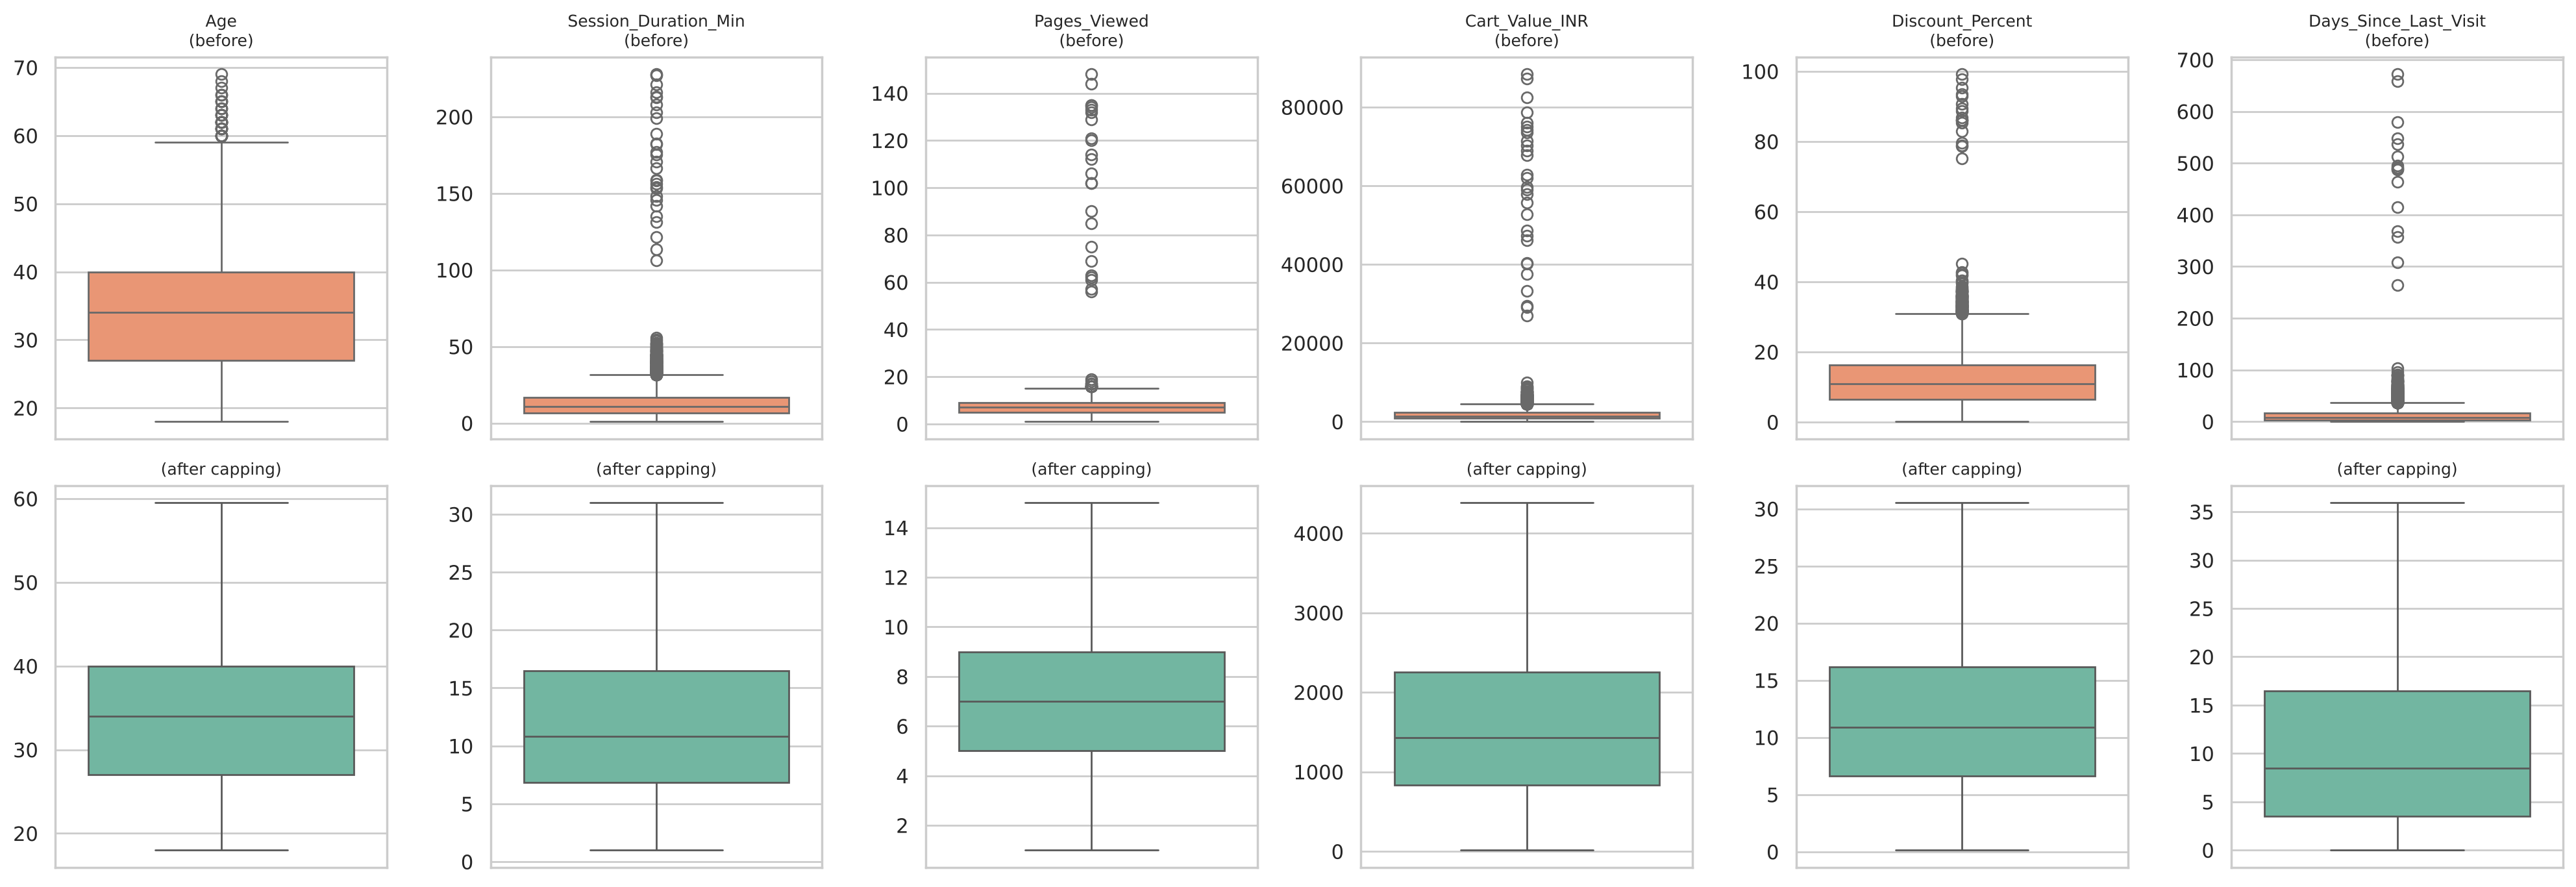

In [12]:
before = X_train[cont_cols]
after = pd.DataFrame(preprocessor.named_transformers_['cont'][:2].transform(X_train[cont_cols]), columns=cont_cols)
cap_tbl = pd.DataFrame({'lower_fence': preprocessor.named_transformers_['cont']['cap'].lower_,
                        'upper_fence': preprocessor.named_transformers_['cont']['cap'].upper_,
                        'n_values_capped': [int(((before[c] > hi) | (before[c] < lo)).sum()) for c, lo, hi in
                            zip(cont_cols, preprocessor.named_transformers_['cont']['cap'].lower_, preprocessor.named_transformers_['cont']['cap'].upper_)]},
                       index=cont_cols).round(2)
display(cap_tbl)
RESULTS['capping'] = cap_tbl.reset_index().rename(columns={'index': 'feature'}).to_dict(orient='records')
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for i, c in enumerate(cont_cols):
    sns.boxplot(y=before[c], ax=axes[0, i], color='#fc8d62'); axes[0, i].set_title(f'{c}\n(before)', fontsize=9); axes[0, i].set_ylabel('')
    sns.boxplot(y=after[c],  ax=axes[1, i], color='#66c2a5'); axes[1, i].set_title('(after capping)', fontsize=9); axes[1, i].set_ylabel('')
savefig('07_outliers_before_after')

**What the preprocessing did (fit on the training data only):**
- **Missing values:** median for numeric columns (robust to the skew), most-frequent category for categoricals.
- **Outliers:** values beyond 1.5 x IQR were capped (winsorised) rather than deleted, so no customers are lost. Capping was applied to the six continuous, skewed features; bounded or small-count features (ratings, email open rate, cart items, orders, returns, products viewed) are left as they are.
- **Encoding:** one-hot with the first level dropped to avoid the dummy-variable trap; unknown categories at prediction time are tolerated.
- **Scaling:** StandardScaler on all numeric features, which puts coefficients on a comparable scale and helps the solver converge.

In [13]:
# Cleaned reference dataset (full data, same rules, unscaled) saved for inspection
clean = df.drop_duplicates().copy(); clean['Pages_Viewed'] = clean['Pages_Viewed'].round()
for c in cont_cols + other_num: clean[c] = clean[c].fillna(clean[c].median())
for c in cat_cols: clean[c] = clean[c].fillna(clean[c].mode()[0])
for c in cont_cols:
    q1, q3 = clean[c].quantile([.25, .75]); iqr = q3 - q1
    clean[c] = clean[c].clip(q1 - 1.5*iqr, q3 + 1.5*iqr)
clean.to_csv(f'{ART_DIR}/ecommerce_cleaned.csv', index=False)
print('Saved cleaned dataset:', clean.shape, '| missing cells left:', int(clean.isna().sum().sum()))

Saved cleaned dataset: (10000, 19) | missing cells left: 0


## 3. Model development

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- Baseline: default Logistic Regression
baseline = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
baseline.fit(X_train, y_train)

# --- Tuned: grid search over regularisation strength, penalty and class weights (5-fold stratified CV, ROC-AUC)
pipe = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(solver='liblinear', max_iter=2000, random_state=RANDOM_STATE))])
param_grid = {'clf__C': [0.001, 0.01, 0.1, 1, 10, 100], 'clf__penalty': ['l1', 'l2'], 'clf__class_weight': [None, 'balanced']}
grid = GridSearchCV(pipe, param_grid, cv=skf, scoring='roc_auc', n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)
best = grid.best_estimator_
print('Best params :', grid.best_params_)
print('Best CV AUC : %.4f' % grid.best_score_)
cvres = pd.DataFrame(grid.cv_results_)[['param_clf__C','param_clf__penalty','param_clf__class_weight','mean_test_score','std_test_score','mean_train_score']]
display(cvres.sort_values('mean_test_score', ascending=False).head(8).round(4))
RESULTS['best_params'] = {k.replace('clf__', ''): (None if v is None else (float(v) if isinstance(v, (int, float)) else v)) for k, v in grid.best_params_.items()}
RESULTS['best_cv_auc'] = float(grid.best_score_)
RESULTS['cv_auc_std'] = float(cvres.sort_values('mean_test_score', ascending=False).iloc[0]['std_test_score'])

Best params : {'clf__C': 1, 'clf__class_weight': None, 'clf__penalty': 'l1'}
Best CV AUC : 0.7282


,param_clf__C,param_clf__penalty,param_clf__class_weight,mean_test_score,std_test_score,mean_train_score
12,1.0,l1,NaN,0.7282,0.0072,0.7324
11,0.1,l2,balanced,0.7281,0.0071,0.7324
9,0.1,l2,NaN,0.7281,0.0071,0.7322
14,1.0,l1,balanced,0.7281,0.0070,0.7325
13,1.0,l2,NaN,0.7280,0.0070,0.7325
16,10.0,l1,NaN,0.7280,0.0071,0.7325
17,10.0,l2,NaN,0.7280,0.0070,0.7325
21,100.0,l2,NaN,0.7280,0.0071,0.7325


### 3.1 Multicollinearity check (VIF)

In [15]:
Xt = preprocessor.transform(X_train)
vif = []
for j, name in enumerate(feature_names):
    others = np.delete(Xt, j, axis=1)
    r2 = LinearRegression().fit(others, Xt[:, j]).score(others, Xt[:, j])
    vif.append((name, 1 / (1 - r2) if r2 < 1 else np.inf))
vif = pd.DataFrame(vif, columns=['feature', 'VIF']).sort_values('VIF', ascending=False).round(3)
display(vif.head(10))
RESULTS['vif_max'] = float(vif.VIF.max()); RESULTS['vif_top'] = vif.head(5).to_dict(orient='records')

,feature,VIF
24,Payment_Method_UPI,2.943
22,Payment_Method_Credit Card,2.697
23,Payment_Method_Debit Card,2.480
16,Traffic_Source_Organic,2.234
25,Payment_Method_Wallet,2.179
17,Traffic_Source_Paid Ads,2.083
19,Traffic_Source_Social Media,1.942
18,Traffic_Source_Referral,1.549
14,Device_Type_Mobile,1.163
15,Device_Type_Tablet,1.163


**Model-selection notes:** the grid search picked **L1 regularisation, C = 1, no class weighting** (CV ROC-AUC = 0.728 +/- 0.007). The VIF check shows no multicollinearity problem (max VIF = 2.9, well below the usual 5-10 warning range), so coefficients can be interpreted safely.

## 4. Evaluation (hold-out test set)

In [16]:
def evaluate(model, Xa, ya, t=0.5):
    p = model.predict_proba(Xa)[:, 1]; pred = (p >= t).astype(int)
    return dict(accuracy=accuracy_score(ya, pred), precision=precision_score(ya, pred), recall=recall_score(ya, pred),
                f1=f1_score(ya, pred), roc_auc=roc_auc_score(ya, p), pr_auc=average_precision_score(ya, p))

rows = {'Baseline (train)': evaluate(baseline, X_train, y_train), 'Baseline (test)': evaluate(baseline, X_test, y_test),
        'Tuned (train)': evaluate(best, X_train, y_train), 'Tuned (test)': evaluate(best, X_test, y_test)}
comp = pd.DataFrame(rows).T.round(4); display(comp)
RESULTS['metrics'] = {k: {m: float(v) for m, v in r.items()} for k, r in rows.items()}
RESULTS['majority_baseline_accuracy'] = float(max(y_test.mean(), 1 - y_test.mean()))
print('Majority-class accuracy on test (naive benchmark): %.4f' % RESULTS['majority_baseline_accuracy'])
print('\nOverfitting check -> train AUC %.4f | CV AUC %.4f | test AUC %.4f' % (rows['Tuned (train)']['roc_auc'], grid.best_score_, rows['Tuned (test)']['roc_auc']))

,accuracy,precision,recall,f1,roc_auc,pr_auc
Baseline (train),0.7008,0.7265,0.8630,0.7889,0.7320,0.8264
Baseline (test),0.7045,0.7279,0.8688,0.7921,0.7411,0.8388
Tuned (train),0.7002,0.7260,0.8632,0.7887,0.7320,0.8264
Tuned (test),0.7035,0.7263,0.8704,0.7919,0.7410,0.8387


Majority-class accuracy on test (naive benchmark): 0.6480

Overfitting check -> train AUC 0.7320 | CV AUC 0.7282 | test AUC 0.7410


              precision    recall  f1-score   support

 No Purchase      0.624     0.396     0.485       704
    Purchase      0.726     0.870     0.792      1296

    accuracy                          0.704      2000
   macro avg      0.675     0.633     0.638      2000
weighted avg      0.690     0.704     0.684      2000



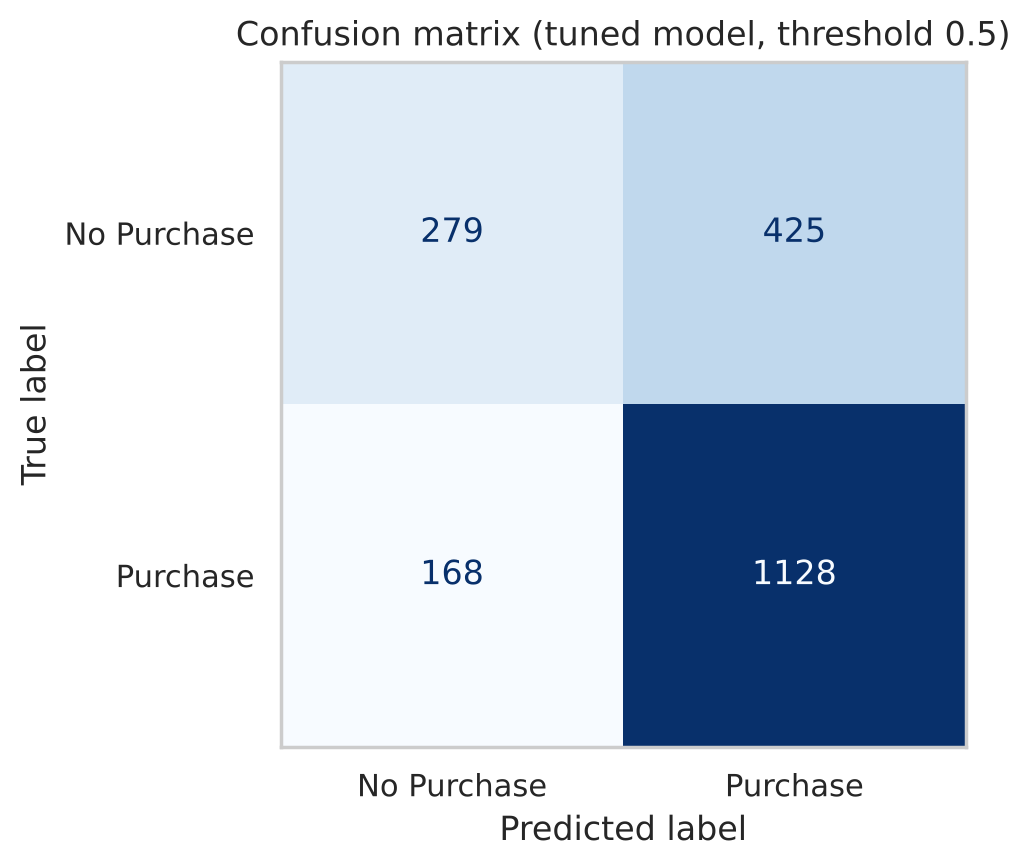

In [17]:
proba_test = best.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)
print(classification_report(y_test, pred_test, target_names=['No Purchase', 'Purchase'], digits=3))
cm = confusion_matrix(y_test, pred_test)
RESULTS['confusion_matrix_0.5'] = cm.tolist()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['No Purchase', 'Purchase']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Confusion matrix (tuned model, threshold 0.5)'); ax.grid(False)
savefig('08_confusion_matrix')

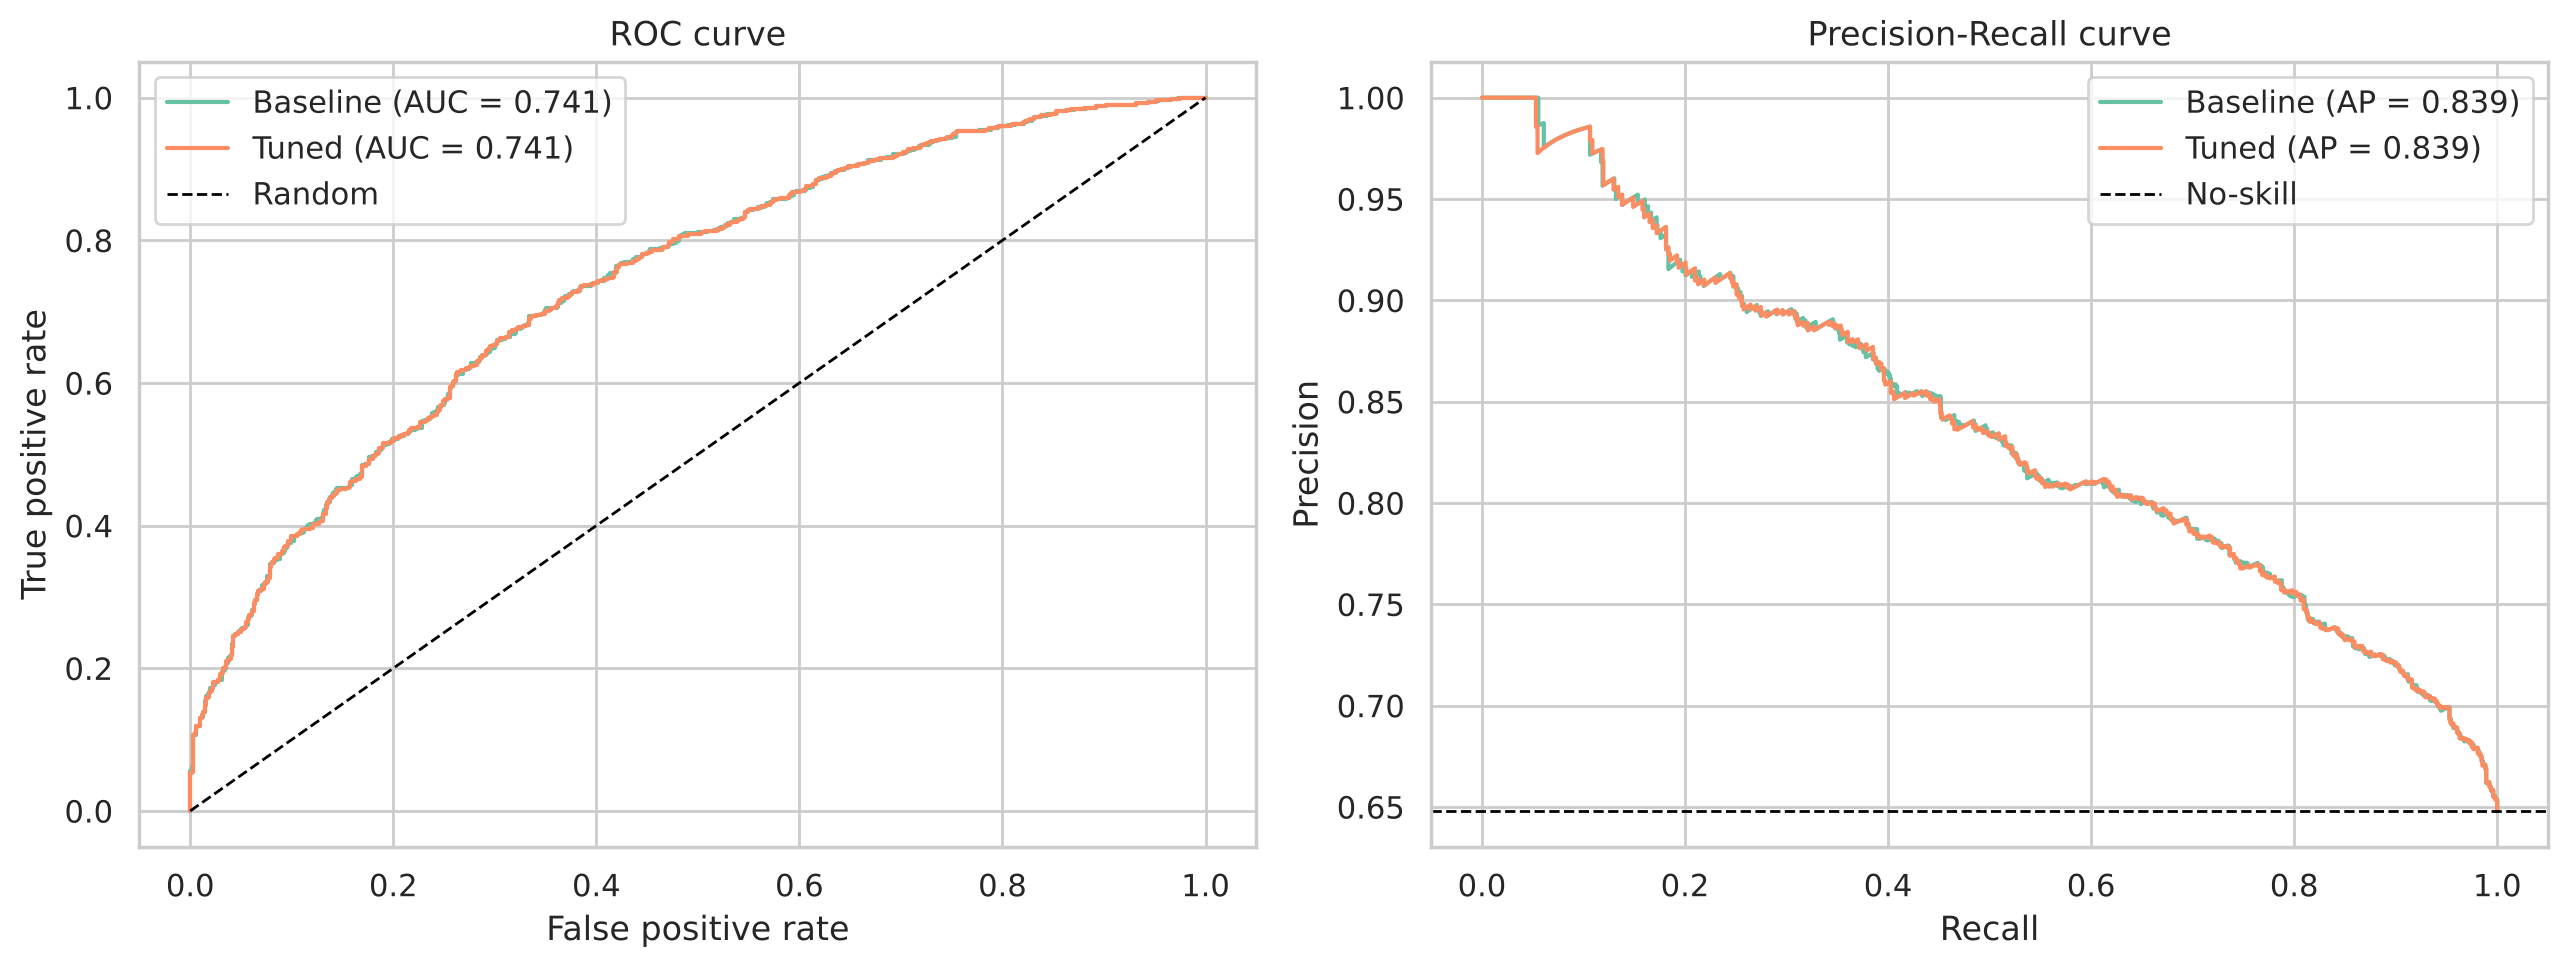

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, m in [('Baseline', baseline), ('Tuned', best)]:
    p = m.predict_proba(X_test)[:, 1]; fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, label=f'{name} (AP = {average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random'); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].set_title('ROC curve'); axes[0].legend()
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label='No-skill'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision-Recall curve'); axes[1].legend()
savefig('09_roc_pr_curves')

### 4.1 Threshold analysis
The default 0.5 cut-off is not necessarily right for the business. The cut-offs below are chosen on **out-of-fold training predictions** (never on the test set), then evaluated on the test set.

,threshold,accuracy,precision,recall,f1,flagged_pct
Default 0.5,0.500,0.704,0.726,0.870,0.792,0.776
F1-optimal (CV),0.400,0.696,0.693,0.954,0.803,0.892
Balanced / Youden (CV),0.628,0.682,0.790,0.694,0.739,0.569


,threshold,accuracy,precision,recall,f1,flagged_pct
0,0.20,0.656,0.653,0.999,0.790,0.991
1,0.25,0.662,0.658,0.994,0.792,0.978
2,0.30,0.674,0.668,0.989,0.797,0.960
3,0.35,0.686,0.680,0.975,0.801,0.930
4,0.40,0.696,0.693,0.954,0.803,0.892
5,0.45,0.703,0.710,0.916,0.800,0.836
6,0.50,0.704,0.726,0.870,0.792,0.776
7,0.55,0.699,0.745,0.813,0.778,0.707
8,0.60,0.693,0.778,0.737,0.757,0.614
9,0.65,0.672,0.800,0.658,0.722,0.533


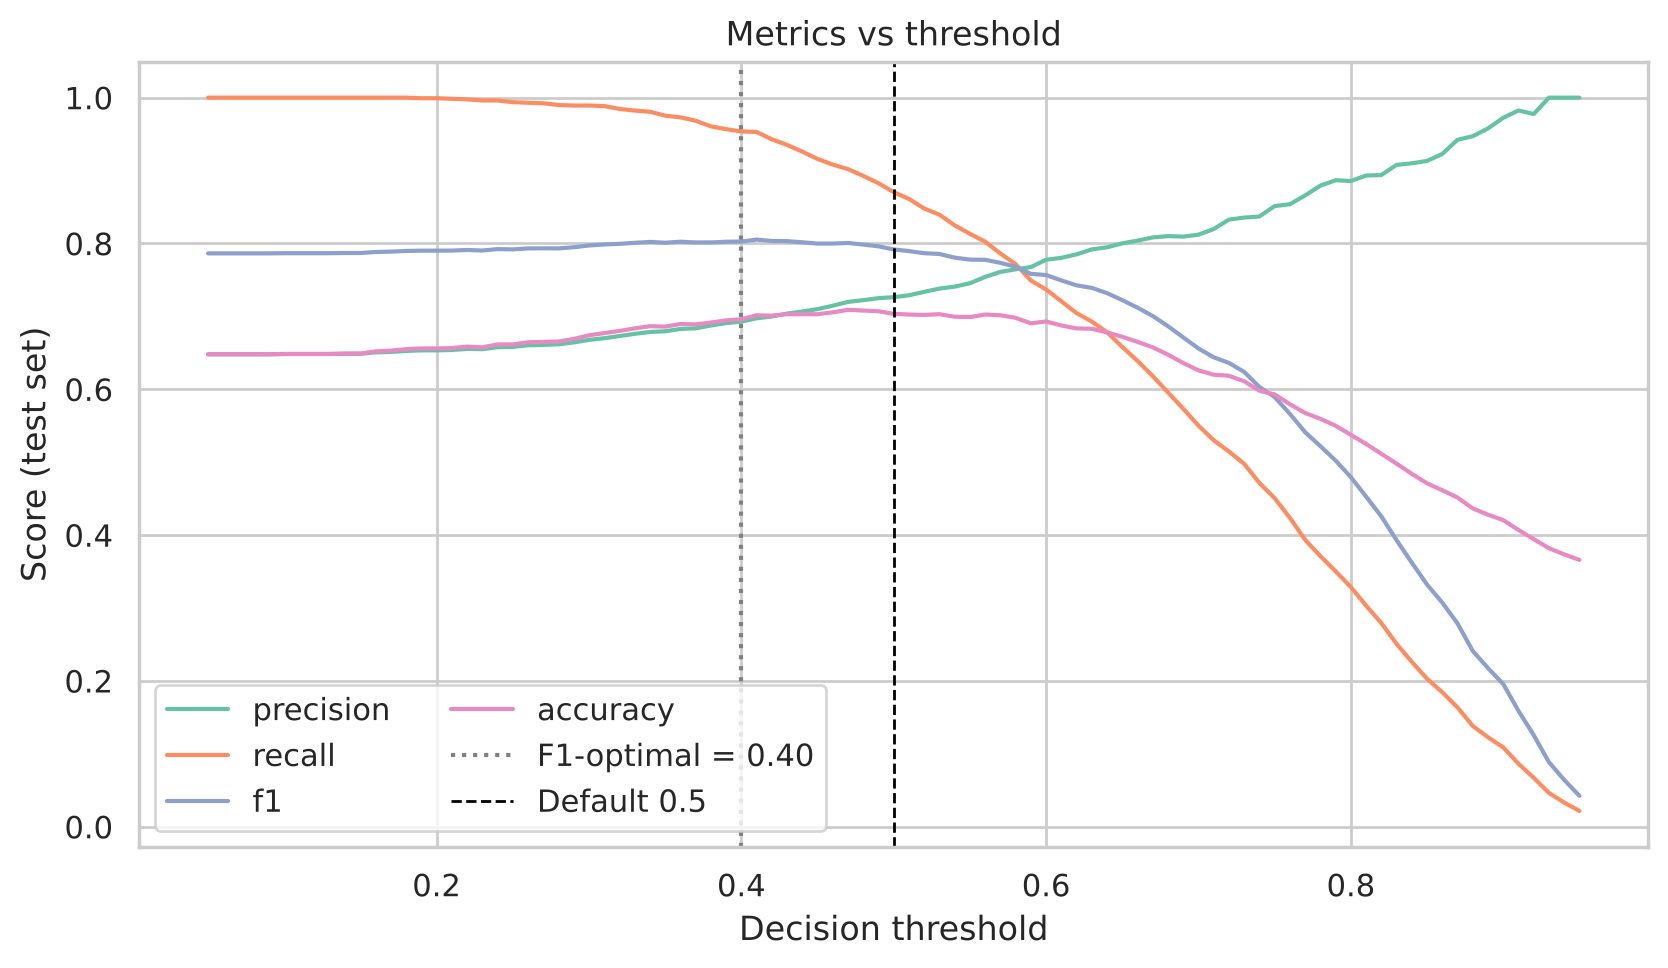

In [19]:
oof = cross_val_predict(best, X_train, y_train, cv=skf, method='predict_proba')[:, 1]
grid_t = np.round(np.arange(0.05, 0.96, 0.01), 2)
f1s = [f1_score(y_train, oof >= t) for t in grid_t]
t_f1 = float(grid_t[int(np.argmax(f1s))])
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof); t_youden = float(thr_o[int(np.argmax(tpr_o - fpr_o))])

def at(t):
    pred = (proba_test >= t).astype(int)
    return dict(threshold=round(t, 3), accuracy=accuracy_score(y_test, pred), precision=precision_score(y_test, pred, zero_division=0),
                recall=recall_score(y_test, pred), f1=f1_score(y_test, pred), flagged_pct=pred.mean())
thr_table = pd.DataFrame([at(0.5), at(t_f1), at(t_youden)], index=['Default 0.5', 'F1-optimal (CV)', 'Balanced / Youden (CV)']).round(3)
display(thr_table)
RESULTS['threshold_table'] = thr_table.reset_index().rename(columns={'index': 'strategy'}).to_dict(orient='records')
RESULTS['t_f1'], RESULTS['t_youden'] = t_f1, t_youden

sweep = pd.DataFrame([at(t) for t in np.arange(0.2, 0.86, 0.05)]).round(3); display(sweep)
RESULTS['threshold_sweep'] = sweep.to_dict(orient='records')
ts = np.arange(0.05, 0.96, 0.01)
curve = pd.DataFrame([at(t) for t in ts])
fig, ax = plt.subplots(figsize=(8.5, 5))
for m in ['precision', 'recall', 'f1', 'accuracy']: ax.plot(curve.threshold, curve[m], label=m)
ax.axvline(t_f1, color='gray', ls=':', label=f'F1-optimal = {t_f1:.2f}'); ax.axvline(0.5, color='k', ls='--', lw=1, label='Default 0.5')
ax.set_xlabel('Decision threshold'); ax.set_ylabel('Score (test set)'); ax.set_title('Metrics vs threshold'); ax.legend(ncol=2)
savefig('10_threshold_analysis')

### Reading the results
- **The tuned model reaches 70.4% accuracy, ROC-AUC 0.741, precision 72.6%, recall 87.0% and F1 0.792 on unseen data.** That beats the 64.8% majority-class benchmark by about 5.6 points and ranks buyers above non-buyers 74% of the time.
- **No overfitting:** train AUC 0.732, CV AUC 0.728, test AUC 0.741 are all aligned.
- **Tuning did not materially improve on the baseline** (test AUC 0.741 vs 0.741). The signal in this dataset is mostly linear and simple, so the default model was already near the best a Logistic Regression can do here.
- **At the default threshold the model is better at finding buyers than non-buyers:** of 704 non-buyers in the test set only 279 are identified (specificity ~40%), while 1,128 of 1,296 buyers are caught. Lowering the threshold to 0.40 pushes recall to 95% (F1 0.803) but flags 89% of customers, so it is only useful if missing a buyer is far costlier than a wasted contact. A 0.63 threshold gives a more selective list (79% precision, 69% recall).
- **Realistic expectations:** the individual features are only weakly predictive, so AUC ~0.74 is a sensible ceiling for a linear model on this data, not a sign of a mistake.

## 5. Interpretation: what drives purchases?
Numeric features are standardised, so an odds ratio is the change in the odds of purchase for a **+1 standard-deviation** increase. For one-hot columns it is the odds relative to the reference category.

,feature,coefficient,odds_ratio
0,Cart_Items,0.6064,1.8338
1,Membership_Type_Premium,0.5340,1.7057
2,Cart_Value_INR,0.4071,1.5025
3,Session_Duration_Min,0.2723,1.3130
4,Pages_Viewed,0.2614,1.2988
5,Products_Viewed,0.2579,1.2942
6,Membership_Type_Regular,0.2380,1.2687
7,Previous_Orders,0.2186,1.2443
8,Discount_Percent,0.1475,1.1590
9,Customer_Rating,0.0872,1.0911


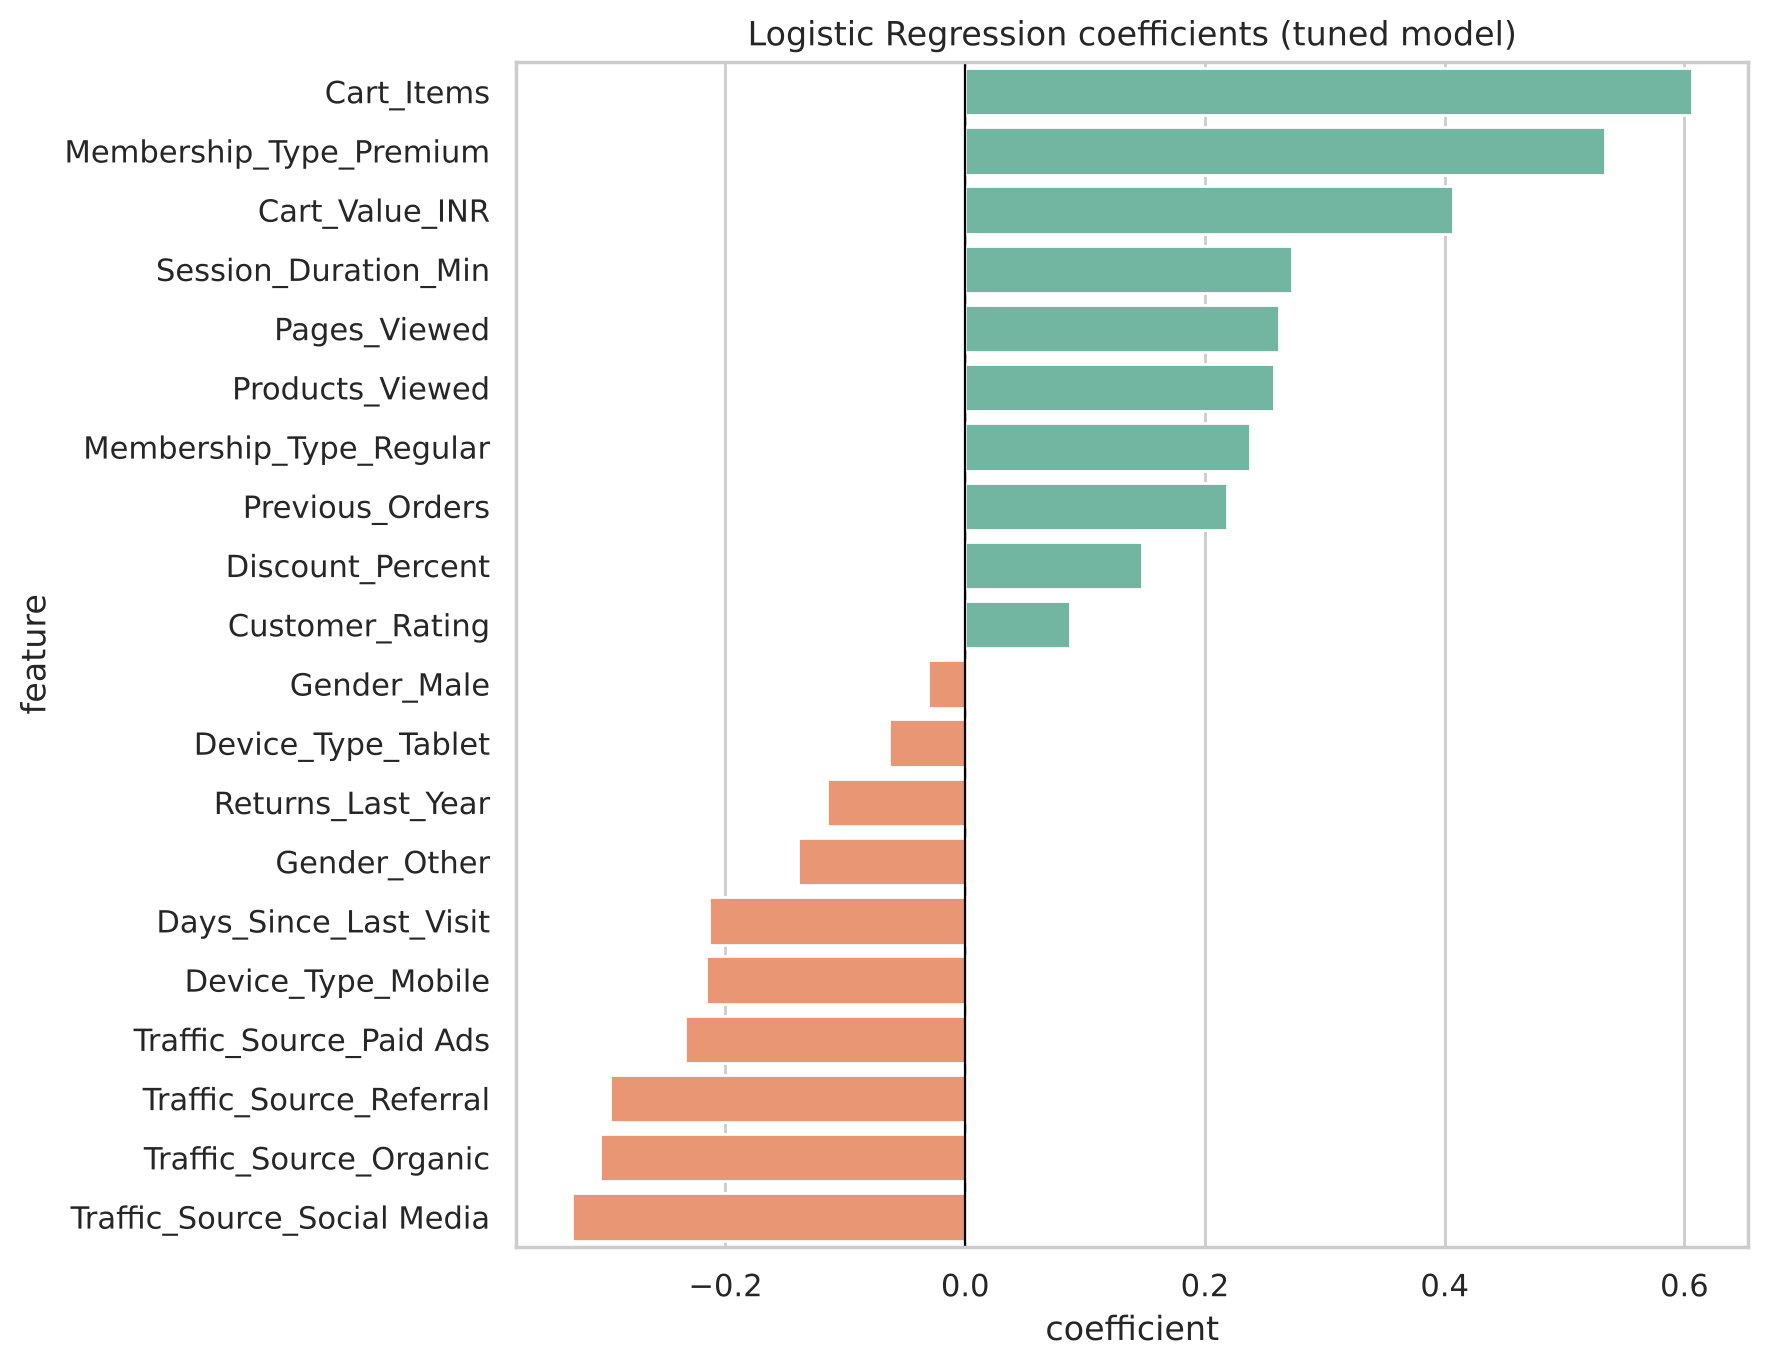

In [20]:
clf = best.named_steps['clf']
coef = pd.DataFrame({'feature': feature_names, 'coefficient': clf.coef_[0]})
coef['odds_ratio'] = np.exp(coef.coefficient); coef = coef.sort_values('coefficient', ascending=False).reset_index(drop=True)
display(coef.round(4))
RESULTS['coefficients'] = coef.round(4).to_dict(orient='records')
top = pd.concat([coef.head(10), coef.tail(10)]).drop_duplicates('feature')
top = top[top.coefficient != 0]
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=top, y='feature', x='coefficient', ax=ax, palette=['#66c2a5' if v > 0 else '#fc8d62' for v in top.coefficient])
ax.axvline(0, color='k', lw=0.8); ax.set_title('Logistic Regression coefficients (tuned model)')
savefig('11_coefficients')

### Business reading of the drivers
**Increase purchase odds** (per +1 SD for numeric features):
- **Cart_Items (+83% odds)**, **Cart_Value (+50%)**: shoppers with fuller, more valuable carts are by far the most likely to buy.
- **Premium membership (+71% vs New)** and **Regular (+27% vs New)**: loyalty tiers convert better.
- **Session duration, pages viewed, products viewed (+29-31% each)** and **Previous orders (+24%)**: engagement and purchase history matter.
- **Discount % (+16%)**: discounts help, but modestly.

**Decrease purchase odds:**
- **Traffic source (vs Email as reference):** Social Media (-28%), Organic (-26%), Referral (-26%) and Paid Ads (-21%) visitors are less likely to buy than email-driven visitors.
- **Mobile (-19% vs Desktop)**: mobile conversion lags desktop.
- **Days since last visit (-19%)** and **Returns last year (-11%)**: lapsed visitors and frequent returners are less likely to buy.

Age, gender and payment method have coefficients close to zero, i.e. no practical effect (L1 regularisation shrank some of them to exactly 0).

## 6. Predicting purchase for new customers

In [21]:
os.makedirs(ART_DIR, exist_ok=True)
joblib.dump(best, f'{ART_DIR}/purchase_model_pipeline.pkl')
json.dump({'recommended_threshold_f1': t_f1, 'balanced_threshold': t_youden, 'default_threshold': 0.5}, open(f'{ART_DIR}/thresholds.json', 'w'), indent=2)
model = joblib.load(f'{ART_DIR}/purchase_model_pipeline.pkl')           # reload to prove the saved pipeline works end-to-end
assert np.allclose(model.predict_proba(X_test)[:, 1], proba_test)

new_customers = pd.DataFrame([
 # Engaged, loyal premium customer with a full cart
 dict(Age=32, Gender='Female', Device_Type='Mobile', Traffic_Source='Email', Membership_Type='Premium', Payment_Method='UPI',
      Session_Duration_Min=18.0, Pages_Viewed=12, Products_Viewed=7, Cart_Items=4, Cart_Value_INR=5200.0, Discount_Percent=15.0,
      Previous_Orders=6, Days_Since_Last_Visit=2.0, Email_Open_Rate=0.80, Customer_Rating=4.5, Returns_Last_Year=0),
 # Window-shopper: new member, short visit, empty cart
 dict(Age=24, Gender='Male', Device_Type='Desktop', Traffic_Source='Social Media', Membership_Type='New', Payment_Method='Wallet',
      Session_Duration_Min=3.0, Pages_Viewed=3, Products_Viewed=1, Cart_Items=0, Cart_Value_INR=400.0, Discount_Percent=5.0,
      Previous_Orders=0, Days_Since_Last_Visit=30.0, Email_Open_Rate=0.10, Customer_Rating=3.2, Returns_Last_Year=1),
 # Typical average customer
 dict(Age=34, Gender='Female', Device_Type='Mobile', Traffic_Source='Organic', Membership_Type='Regular', Payment_Method='Credit Card',
      Session_Duration_Min=10.8, Pages_Viewed=7, Products_Viewed=4, Cart_Items=1, Cart_Value_INR=1430.0, Discount_Percent=10.8,
      Previous_Orders=3, Days_Since_Last_Visit=8.5, Email_Open_Rate=0.50, Customer_Rating=3.8, Returns_Last_Year=0),
 # Lapsed customer with many returns
 dict(Age=45, Gender='Male', Device_Type='Tablet', Traffic_Source='Paid Ads', Membership_Type='New', Payment_Method='Cash on Delivery',
      Session_Duration_Min=5.0, Pages_Viewed=4, Products_Viewed=2, Cart_Items=0, Cart_Value_INR=900.0, Discount_Percent=8.0,
      Previous_Orders=1, Days_Since_Last_Visit=60.0, Email_Open_Rate=0.15, Customer_Rating=2.9, Returns_Last_Year=3),
 # Record with missing values and outlier-sized numbers (shows the pipeline copes with messy input)
 dict(Age=np.nan, Gender=None, Device_Type='Mobile', Traffic_Source=None, Membership_Type='Premium', Payment_Method='UPI',
      Session_Duration_Min=np.nan, Pages_Viewed=9, Products_Viewed=5, Cart_Items=2, Cart_Value_INR=60000.0, Discount_Percent=12.0,
      Previous_Orders=4, Days_Since_Last_Visit=400.0, Email_Open_Rate=0.6, Customer_Rating=np.nan, Returns_Last_Year=0),
])
new_customers.insert(0, 'Profile', ['Engaged premium', 'Window shopper', 'Average customer', 'Lapsed / high returns', 'Messy record (NaNs, outliers)'])
pnew = model.predict_proba(new_customers.drop(columns='Profile'))[:, 1]
out = new_customers[['Profile', 'Membership_Type', 'Cart_Items', 'Products_Viewed', 'Previous_Orders']].copy()
out['P(purchase)'] = pnew.round(3)
out['Pred @0.5'] = np.where(pnew >= 0.5, 'Purchase', 'No Purchase')
out[f'Pred @{t_f1:.2f} (F1-opt)'] = np.where(pnew >= t_f1, 'Purchase', 'No Purchase')
display(out)
RESULTS['new_customers'] = out.to_dict(orient='records')

,Profile,Membership_Type,Cart_Items,Products_Viewed,Previous_Orders,P(purchase),Pred @0.5,Pred @0.40 (F1-opt)
0,Engaged premium,Premium,4,7,6,0.996,Purchase,Purchase
1,Window shopper,New,0,1,0,0.048,No Purchase,No Purchase
2,Average customer,Regular,1,4,3,0.597,Purchase,Purchase
3,Lapsed / high returns,New,0,2,1,0.064,No Purchase,No Purchase
4,"Messy record (NaNs, outliers)",Premium,2,5,4,0.908,Purchase,Purchase


## 7. Save results

In [22]:
def to_py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(RESULTS, open(f'{ART_DIR}/results.json', 'w'), indent=2, default=to_py)
print('Saved: model pipeline, thresholds, cleaned dataset, results.json, figures/')

Saved: model pipeline, thresholds, cleaned dataset, results.json, figures/


## 8. Business recommendations & limitations
1. **Target high-intent carts first.** Customers with 3+ cart items buy 79-100% of the time. Prioritise cart-abandonment reminders for 1-2 item carts, where a nudge has the most room to convert.
2. **Grow Premium membership.** Premium customers convert at 72% vs 61% for New. Offer upgrade incentives to Regular and New members with strong engagement.
3. **Invest in email.** Email-sourced visitors have the highest purchase rate (70%). Use email to re-engage lapsed customers; reallocate part of the Social/Paid budget towards lead capture into email lists.
4. **Fix the mobile experience.** Mobile (the majority of sessions) converts below desktop and tablet; simplify checkout and cart flow on mobile.
5. **Re-engage lapsed visitors within 2 weeks.** Purchase rate falls from 68% (visited within a week) to 55% (30+ days away).
6. **Use the model to rank, not just classify.** Score every active session with `P(purchase)` and use thresholds by campaign type: ~0.40 for broad, low-cost campaigns (95% of buyers reached); ~0.63 for costly offers such as high discounts (79% precision).
7. **Audit returns.** Frequent returners are less likely to buy; investigate product and fulfilment causes.

**Limitations & next steps**
- Predictive power is moderate (AUC 0.74): behaviour captured in this dataset explains only part of purchase intent. Adding session-level events (cart additions timing, search terms, product categories, price sensitivity) would likely help more than model changes.
- 2,105 records with 0 cart items but a positive cart value should be investigated at the source (possible logging issue).
- Try non-linear models (Random Forest, Gradient Boosting), interaction terms and calibration to see whether they add lift, but keep Logistic Regression as the interpretable benchmark.
- Validate on future data (time-based split) before deploying, and monitor drift.